<a href="https://colab.research.google.com/github/CristianChuquin/emg-quadriceps-fatigue/blob/main/pre_procesamiento_de_datos_y_modelo_completo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [127]:
# ============================================================
# SETUP — auto-detecta datos crudos (Colab/Drive  ó  repo limpio)
# ============================================================
import os
from pathlib import Path

# En Colab: montar Drive primero (idempotente)
if not Path("/content/drive/MyDrive").is_dir():
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except ImportError:
        pass  # no estamos en Colab

BASE_DIR   = Path.cwd()
DATA_LOCAL = BASE_DIR / "data" / "raw"

# Si data/raw no existe y estamos en Colab con Drive montado,
# crea un symlink a la carpeta original en Drive (una sola vez).
if not DATA_LOCAL.exists():
    drive_raw = Path("/content/drive/MyDrive/EMG - RAW data")
    if drive_raw.is_dir():
        (BASE_DIR / "data").mkdir(exist_ok=True)
        DATA_LOCAL.symlink_to(drive_raw, target_is_directory=True)
        print(f"Symlink creado: {DATA_LOCAL} -> {drive_raw}")

DATA_RAW       = DATA_LOCAL
DATA_PROCESSED = BASE_DIR / "data" / "processed"
RESULTS_DIR    = BASE_DIR / "resultados"
GRAFICAS_DIR   = BASE_DIR / "graficas"

for d in [DATA_PROCESSED, RESULTS_DIR, GRAFICAS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

if not DATA_RAW.is_dir():
    raise FileNotFoundError(
        f"Falta la carpeta de datos: {DATA_RAW}\n"
        f"· En Colab: monta Drive y ten 'EMG - RAW data' con sujeto1..sujeto15 dentro.\n"
        f"· En repo limpio: coloca los CSV en data/raw/sujetoN/R1_dr_sujetoN.csv, etc."
    )

print("Datos crudos:  ", DATA_RAW, "| es symlink:", DATA_RAW.is_symlink())
print("Procesados:    ", DATA_PROCESSED)
print("Gráficas:      ", GRAFICAS_DIR)

Datos crudos:   /content/data/raw | es symlink: True
Procesados:     /content/data/processed
Gráficas:       /content/graficas


In [128]:
import os
subs = sorted([p.name for p in DATA_RAW.iterdir() if p.is_dir()])
print(f"{len(subs)} sujetos:", subs[:3], "...", subs[-1])
assert len(subs) == 15, "Esperaba 15 sujetos"
print("Primer archivo de sujeto1:", sorted(os.listdir(DATA_RAW / "sujeto1"))[:2])

15 sujetos: ['sujeto1', 'sujeto10', 'sujeto11'] ... sujeto9
Primer archivo de sujeto1: ['R1_dr_sujeto1.csv', 'R1_iz_sujeto1.csv']


In [129]:
import os

RAIZ = "/content/drive/MyDrive"
print(f"Contenido de {RAIZ}:")
for name in sorted(os.listdir(RAIZ)):
    full = os.path.join(RAIZ, name)
    kind = "DIR " if os.path.isdir(full) else "file"
    print(f"  [{kind}] {name}")

Contenido de /content/drive/MyDrive:
  [DIR ] Actividad_ Taller de Comunicación
  [DIR ] BIOMECANICA
  [DIR ] Carpeta sin título
  [DIR ] Colab Notebooks
  [file] Copia de fig1_training_curves.png
  [file] Copia de fig2_confusion_matrix.png
  [file] Copia de fig3_dwt_filtering.png
  [file] Copia de fig4_class_metrics.png
  [DIR ] DAAD
  [DIR ] Docentes
  [DIR ] EMG - RAW data
  [DIR ] EMG_RAW data_procesada
  [file] Entrevista.gdoc
  [DIR ] Mate Sup_Laboratories
  [file] Sitio sin título.gsite
  [file] X_signals.npy
  [file] df_valido.csv
  [file] ecg_model_12ch_best.keras
  [file] ecg_model_best.keras
  [file] features_dataset_bilateral.csv
  [file] features_dataset_bilateral_2sujetos.csv
  [file] features_dataset_completo.csv
  [file] features_dataset_completo_2sujetos.csv
  [file] mejor_modelo.h5
  [file] mejor_modelo_smote.h5
  [file] mejor_modelo_v2.h5
  [file] modelo_int8.tflite
  [file] modelo_int8_3clases.tflite
  [DIR ] ptb-xl-a-large-publicly-available-electrocardiography-

In [130]:
import os

ruta_datos = "/content/drive/MyDrive/EMG - RAW data"

print(f"Existe: {os.path.isdir(ruta_datos)}")
items = sorted(os.listdir(ruta_datos))
print(f"Contiene ({len(items)}): {items}")

sujetos = [x for x in items if x.lower().startswith("sujeto")]
print(f"\nSubcarpetas 'sujeto*': {len(sujetos)} -> {sujetos}")

# Mira dentro de un sujeto cualquiera
if sujetos:
    primer = os.path.join(ruta_datos, sujetos[0])
    print(f"\nContenido de {sujetos[0]}:")
    for f in sorted(os.listdir(primer))[:10]:
        print(f"  {f}")

Existe: True
Contiene (15): ['sujeto1', 'sujeto10', 'sujeto11', 'sujeto12', 'sujeto13', 'sujeto14', 'sujeto15', 'sujeto2', 'sujeto3', 'sujeto4', 'sujeto5', 'sujeto6', 'sujeto7', 'sujeto8', 'sujeto9']

Subcarpetas 'sujeto*': 15 -> ['sujeto1', 'sujeto10', 'sujeto11', 'sujeto12', 'sujeto13', 'sujeto14', 'sujeto15', 'sujeto2', 'sujeto3', 'sujeto4', 'sujeto5', 'sujeto6', 'sujeto7', 'sujeto8', 'sujeto9']

Contenido de sujeto1:
  R1_dr_sujeto1.csv
  R1_iz_sujeto1.csv
  R2_dr_sujeto1.csv
  R2_iz_sujeto1.csv
  R3_dr_sujeto1.csv
  R3_iz_sujeto1.csv
  R4_dr_sujeto1.csv
  R4_iz_sujeto1.csv
  R5_dr_sujeto1.csv
  R5_iz_sujeto1.csv


In [131]:
import os
import glob
import numpy as np
import pandas as pd
from scipy.signal import welch

def procesar_dataset_completo(ruta_base):
    print("Iniciando procesamiento...")
    todos_los_datos = []

    # Configuración (Basado en EMG)
    FS = 1000 # Frecuencia de muestreo (ajusta si es diferente)
    WIN = int(0.25 * FS)
    HOP = int(0.125 * FS)

    # Buscar carpetas de sujetos
    carpetas_sujetos = sorted(glob.glob(os.path.join(ruta_base, "sujeto*")))

    if not carpetas_sujetos:
        print("❌ No se encontraron carpetas.")
        return pd.DataFrame()

    for carpeta in carpetas_sujetos:
        sujeto = os.path.basename(carpeta)
        print(f"Procesando {sujeto}...")

        # Buscar archivos _dr_
        archivos_dr = sorted(glob.glob(os.path.join(carpeta, f"*_dr_{sujeto}.csv")))

        for arch_dr in archivos_dr:
            nombre = os.path.basename(arch_dr)
            repeticion = nombre.split('_')[0]
            arch_iz = arch_dr.replace('_dr_', '_iz_')

            if not os.path.exists(arch_iz):
                continue

            try:
                # CORRECCIÓN AQUÍ: Usamos iloc[:, 1] para tomar la SEGUNDA columna (el EMG)
                # en lugar de la primera (que suele ser el Tiempo).
                sig_dr = pd.read_csv(arch_dr).iloc[:, 1].values
                sig_iz = pd.read_csv(arch_iz).iloc[:, 1].values

                features_dr = []
                features_iz = []

                # Ventaneo
                for start in range(0, min(len(sig_dr), len(sig_iz)) - WIN + 1, HOP):
                    seg_dr = sig_dr[start:start+WIN]
                    seg_iz = sig_iz[start:start+WIN]
                    time_s = round((start + WIN) / FS, 3)

                    def calc_feats(seg):
                        rms = np.sqrt(np.mean(seg**2))
                        mav = np.mean(np.abs(seg))
                        wl = np.sum(np.abs(np.diff(seg)))
                        f, Pxx = welch(seg, fs=FS, nperseg=min(len(seg), 256))
                        mnf = np.sum(f * Pxx) / (np.sum(Pxx) + 1e-9)
                        cum = np.cumsum(Pxx)
                        mdf = f[np.searchsorted(cum, cum[-1] / 2.0)]
                        return rms, mav, wl, mdf, mnf

                    r_dr, m_dr, w_dr, mdf_dr, mnf_dr = calc_feats(seg_dr)
                    r_iz, m_iz, w_iz, mdf_iz, mnf_iz = calc_feats(seg_iz)

                    features_dr.append({'time_s': time_s, 'RMS': r_dr, 'MAV': m_dr, 'WL': w_dr, 'MDF': mdf_dr, 'MNF': mnf_dr, 'sujeto': sujeto, 'repeticion': repeticion, 'lado': 'derecha'})
                    features_iz.append({'time_s': time_s, 'RMS': r_iz, 'MAV': m_iz, 'WL': w_iz, 'MDF': mdf_iz, 'MNF': mnf_iz, 'sujeto': sujeto, 'repeticion': repeticion, 'lado': 'izquierda'})

                df_dr = pd.DataFrame(features_dr)
                df_iz = pd.DataFrame(features_iz)

                # Calcular ratio y diferencia (Bilateral)
                df_dr['RMS_ratio_dr_iz'] = df_dr['RMS'] / (df_iz['RMS'] + 1e-9)
                df_dr['MDF_diff_dr_iz'] = df_dr['MDF'] - df_iz['MDF']

                # Asignar Etiqueta por tercios (0, 1, 2 - fatiga)
                n = len(df_dr)
                df_dr['label'] = 0
                df_dr.loc[n//3 : 2*n//3, 'label'] = 1
                df_dr.loc[2*n//3 :, 'label'] = 2

                todos_los_datos.append(df_dr)

            except Exception as e:
                print(f"Error en {nombre}: {e}")

    if todos_los_datos:
        return pd.concat(todos_los_datos, ignore_index=True)
    return pd.DataFrame()

Diseño de filtros, Ventaneo + extracción de características (extraer_caracteristicas_ventana), Procesamiento del dataset completo

In [132]:
# ============================================================
# EJECUCIÓN — ruta forzada aquí (ignora globals previos)
# ============================================================

# RUTA FORZADA (sin depender de Celda 0):
ruta_datos  = "/content/drive/MyDrive/EMG - RAW data"
ruta_salida = "/content/drive/MyDrive/EMG_RAW data_procesada"

# Verificar que Drive está montado
if not os.path.isdir("/content/drive/MyDrive"):
    raise RuntimeError("Drive no está montado. Ejecuta primero: from google.colab import drive; drive.mount('/content/drive')")

os.makedirs(ruta_salida, exist_ok=True)

# Verificar rutas
assert os.path.isdir(ruta_datos), f"NO existe: {ruta_datos}"
subs = sorted([f.name for f in os.scandir(ruta_datos) if f.is_dir()])
print(f"OK. {len(subs)} subcarpetas: {subs}")
assert len(subs) == 15, f"Se esperaban 15 sujetos, encontré {len(subs)}"

print("\nIniciando el procesamiento general del dataset...")
print(f"Ruta de entrada: {ruta_datos}")
df_resultado = procesar_dataset_completo(ruta_datos)

if not df_resultado.empty:
    print("\n¡Procesamiento exitoso!")
    print(f"Total de ventanas de características generadas: {len(df_resultado)}")
    print(df_resultado.head())

    output_file = os.path.join(ruta_salida, "features_dataset_completo.csv")
    df_resultado.to_csv(output_file, index=False)
    print(f"Dataset consolidado guardado en: {output_file}")
else:
    print("No se pudieron generar datos. Revisa la ruta de las carpetas.")

OK. 15 subcarpetas: ['sujeto1', 'sujeto10', 'sujeto11', 'sujeto12', 'sujeto13', 'sujeto14', 'sujeto15', 'sujeto2', 'sujeto3', 'sujeto4', 'sujeto5', 'sujeto6', 'sujeto7', 'sujeto8', 'sujeto9']

Iniciando el procesamiento general del dataset...
Ruta de entrada: /content/drive/MyDrive/EMG - RAW data
Iniciando procesamiento...
Procesando sujeto1...
Procesando sujeto10...
Procesando sujeto11...
Procesando sujeto12...
Procesando sujeto13...
Procesando sujeto14...
Procesando sujeto15...
Procesando sujeto2...
Procesando sujeto3...
Procesando sujeto4...
Procesando sujeto5...
Procesando sujeto6...
Procesando sujeto7...
Procesando sujeto8...
Procesando sujeto9...

¡Procesamiento exitoso!
Total de ventanas de características generadas: 14205
   time_s       RMS    MAV     WL    MDF         MNF   sujeto repeticion  \
0   0.250  3.130495  2.512  578.0  204.0  226.006177  sujeto1         R1   
1   0.375  3.453115  2.804  661.0  124.0  179.791659  sujeto1         R1   
2   0.500  3.305753  2.616  649.

Visualización exploratoria de los datos

Cargado: /content/drive/MyDrive/EMG_RAW data_procesada/features_dataset_completo.csv
Shape: (14205, 12)
Sujetos: 14  |  Repeticiones: ['R1', 'R2', 'R3', 'R4', 'R5']

Ventanas del ejemplo (sujeto1, R1, derecha): 246


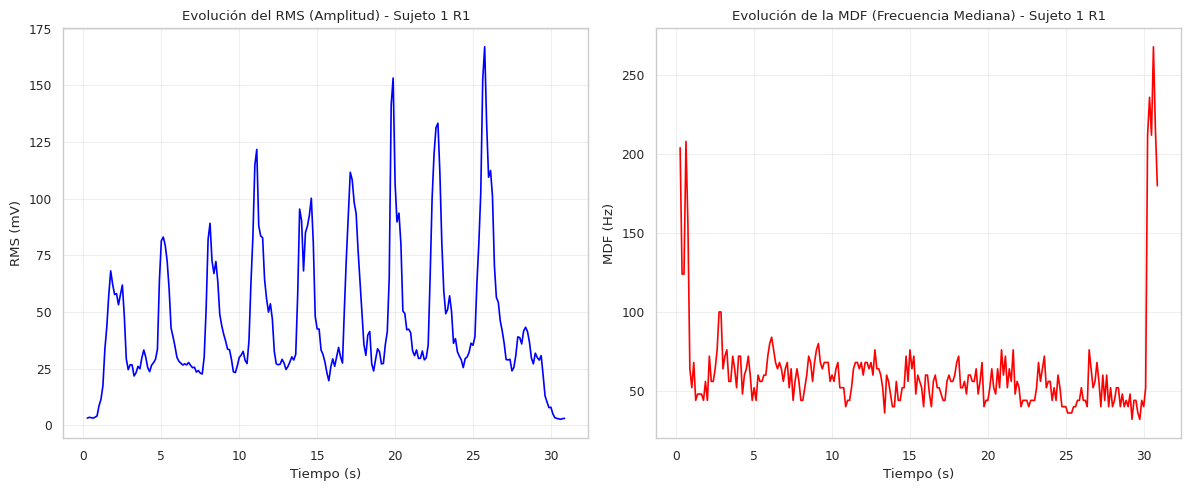

In [133]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# === RUTA FORZADA (no depende de globals previos) ===
ruta_salida = "/content/drive/MyDrive/EMG_RAW data_procesada"
ruta_csv    = os.path.join(ruta_salida, "features_dataset_completo.csv")

# Verificar que el archivo existe antes de leerlo
assert os.path.isfile(ruta_csv), (
    f"NO existe: {ruta_csv}\n"
    f"¿Corriste el Bloque 1 y guardó bien? Contenido actual de la carpeta:\n"
    f"{os.listdir(ruta_salida) if os.path.isdir(ruta_salida) else 'la carpeta tampoco existe'}"
)

# Cargar
df_features = pd.read_csv(ruta_csv)
print(f"Cargado: {ruta_csv}")
print(f"Shape: {df_features.shape}")
print(f"Sujetos: {df_features['sujeto'].nunique()}  |  Repeticiones: {sorted(df_features['repeticion'].unique())}")

# Filtrar ejemplo
ejemplo = df_features[(df_features['sujeto'] == 'sujeto1') &
                      (df_features['repeticion'] == 'R1') &
                      (df_features['lado'] == 'derecha')].copy()

print(f"\nVentanas del ejemplo (sujeto1, R1, derecha): {len(ejemplo)}")
assert not ejemplo.empty, (
    "El filtro no devolvió filas. Revisa si el sujeto/repetición/lado existen. "
    f"Lados disponibles: {df_features['lado'].unique()}"
)

# Graficar
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(ejemplo['time_s'], ejemplo['RMS'], color='blue')
plt.title("Evolución del RMS (Amplitud) - Sujeto 1 R1")
plt.xlabel("Tiempo (s)")
plt.ylabel("RMS (mV)")
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(ejemplo['time_s'], ejemplo['MDF'], color='red')
plt.title("Evolución de la MDF (Frecuencia Mediana) - Sujeto 1 R1")
plt.xlabel("Tiempo (s)")
plt.ylabel("MDF (Hz)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Pipeline bilateral → dataset de entrenamiento principal

In [134]:
import os
import glob
import numpy as np
import pandas as pd
import scipy.signal as signal

def butter_bandpass(lowcut, highcut, fs, order=4):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = signal.butter(order, [low, high], btype='band')
    return b, a

def butter_notch(notch_freq, fs, quality_factor=30.0):
    nyq = 0.5 * fs
    freq = notch_freq / nyq
    b, a = signal.iirnotch(freq, quality_factor)
    return b, a

def aplicar_filtros_emg(data, fs=1000):
    b_bp, a_bp = butter_bandpass(lowcut=20.0, highcut=450.0, fs=fs, order=4)
    filtered = signal.filtfilt(b_bp, a_bp, data)
    b_notch, a_notch = butter_notch(notch_freq=60.0, fs=fs)
    filtered = signal.filtfilt(b_notch, a_notch, filtered)
    return filtered

def extraer_caracteristicas_ventana(time_arr, signal_arr, fs=1000, window_sec=0.25, overlap=0.5):
    win_len = int(window_sec * fs)
    step = int(win_len * (1 - overlap))
    features_out = []

    if len(signal_arr) < win_len:
        return pd.DataFrame()

    for start in range(0, len(signal_arr) - win_len, step):
        window = signal_arr[start:start + win_len]
        t_center = time_arr[start + win_len // 2]

        rms = np.sqrt(np.mean(window**2))
        mav = np.mean(np.abs(window))
        wl = np.sum(np.abs(np.diff(window)))

        freqs, psd = signal.welch(window, fs=fs, nperseg=min(len(window), 256))
        total_power = np.sum(psd)

        if total_power > 0:
            cum_power = np.cumsum(psd)
            mdf_idx = np.where(cum_power >= total_power / 2)[0][0]
            mdf = freqs[mdf_idx]
            mnf = np.sum(freqs * psd) / total_power
        else:
            mdf = 0.0
            mnf = 0.0

        features_out.append({
            'time_s': t_center, 'RMS': rms, 'MAV': mav,
            'WL': wl, 'MDF': mdf, 'MNF': mnf
        })

    return pd.DataFrame(features_out)

def procesar_con_bilateralidad(data_dir):
    carpetas_sujetos = sorted([f.path for f in os.scandir(data_dir) if f.is_dir()])
    todos_los_datos = []

    for carpeta_sujeto in carpetas_sujetos:
        nombre_sujeto = os.path.basename(carpeta_sujeto)
        print(f"Procesando bilateralidad para: {nombre_sujeto}...")

        archivos_csv = glob.glob(os.path.join(carpeta_sujeto, "*.csv"))
        repeticiones_dict = {}

        for archivo in archivos_csv:
            nombre_archivo = os.path.basename(archivo)
            if "_dr_" in nombre_archivo:
                lado = "derecha"
            elif "_iz_" in nombre_archivo:
                lado = "izquierda"
            else:
                continue

            repeticion = nombre_archivo.split('_')[0]

            df_raw = pd.read_csv(archivo)
            if 'Voltage_mV' not in df_raw.columns or 'Relative_Time_s' not in df_raw.columns:
                continue

            signal_clean = aplicar_filtros_emg(df_raw['Voltage_mV'].values, fs=1000)
            df_features = extraer_caracteristicas_ventana(df_raw['Relative_Time_s'].values, signal_clean)

            if df_features.empty:
                continue

            n_v = len(df_features)
            tercio = n_v // 3
            labels = [0 if i < tercio else (1 if i < 2*tercio else 2) for i in range(n_v)]
            df_features['label'] = labels
            df_features['sujeto'] = nombre_sujeto
            df_features['repeticion'] = repeticion
            df_features['lado'] = lado

            if repeticion not in repeticiones_dict:
                repeticiones_dict[repeticion] = {}
            repeticiones_dict[repeticion][lado] = df_features

        for rep, lados in repeticiones_dict.items():
            if 'derecha' in lados and 'izquierda' in lados:
                df_dr = lados['derecha'].reset_index(drop=True)
                df_iz = lados['izquierda'].reset_index(drop=True)

                min_len = min(len(df_dr), len(df_iz))
                df_dr = df_dr.iloc[:min_len].copy()
                df_iz = df_iz.iloc[:min_len].copy()

                df_dr['RMS_ratio_dr_iz'] = df_dr['RMS'] / (df_iz['RMS'] + 1e-6)
                df_dr['MDF_diff_dr_iz'] = df_dr['MDF'] - df_iz['MDF']
                df_iz['RMS_ratio_dr_iz'] = df_dr['RMS_ratio_dr_iz']
                df_iz['MDF_diff_dr_iz'] = df_dr['MDF_diff_dr_iz']

                todos_los_datos.append(df_dr)
                todos_los_datos.append(df_iz)
            else:
                for lado_key, df_l in lados.items():
                    df_l['RMS_ratio_dr_iz'] = np.nan
                    df_l['MDF_diff_dr_iz'] = np.nan
                    todos_los_datos.append(df_l)

    if todos_los_datos:
        return pd.concat(todos_los_datos, ignore_index=True)
    return pd.DataFrame()


# ============================================================
# EJECUCIÓN — ruta forzada (sin if __name__, sin Windows)
# ============================================================

ruta_datos  = "/content/drive/MyDrive/EMG - RAW data"
ruta_salida = "/content/drive/MyDrive/EMG_RAW data_procesada"

# Verificar Drive montado y rutas correctas
if not os.path.isdir("/content/drive/MyDrive"):
    raise RuntimeError("Drive no montado. Ejecuta: from google.colab import drive; drive.mount('/content/drive')")

os.makedirs(ruta_salida, exist_ok=True)
assert os.path.isdir(ruta_datos), f"NO existe: {ruta_datos}"

print(f"Ruta de entrada: {ruta_datos}")
df_bilateral = procesar_con_bilateralidad(ruta_datos)

if not df_bilateral.empty:
    out = os.path.join(ruta_salida, "features_dataset_bilateral.csv")
    df_bilateral.to_csv(out, index=False)
    print(f"\n¡Dataset bilateral guardado en: {out}!")
    print(f"Shape: {df_bilateral.shape}")
    print(df_bilateral[['sujeto', 'repeticion', 'lado', 'RMS', 'RMS_ratio_dr_iz']].head())
else:
    print("No se generó el dataset bilateral.")

Ruta de entrada: /content/drive/MyDrive/EMG - RAW data
Procesando bilateralidad para: sujeto1...
Procesando bilateralidad para: sujeto10...
Procesando bilateralidad para: sujeto11...
Procesando bilateralidad para: sujeto12...
Procesando bilateralidad para: sujeto13...
Procesando bilateralidad para: sujeto14...
Procesando bilateralidad para: sujeto15...
Procesando bilateralidad para: sujeto2...
Procesando bilateralidad para: sujeto3...
Procesando bilateralidad para: sujeto4...
Procesando bilateralidad para: sujeto5...
Procesando bilateralidad para: sujeto6...
Procesando bilateralidad para: sujeto7...
Procesando bilateralidad para: sujeto8...
Procesando bilateralidad para: sujeto9...

¡Dataset bilateral guardado en: /content/drive/MyDrive/EMG_RAW data_procesada/features_dataset_bilateral.csv!
Shape: (31021, 12)
    sujeto repeticion     lado       RMS  RMS_ratio_dr_iz
0  sujeto1         R1  derecha  1.656840         0.911640
1  sujeto1         R1  derecha  2.076562         1.294877
2  su

Auditoría del dataset

In [135]:
import os
import pandas as pd

# === RUTA ABSOLUTA (Drive) ===
ruta_salida = "/content/drive/MyDrive/EMG_RAW data_procesada"
ruta_csv    = os.path.join(ruta_salida, "features_dataset_bilateral.csv")

# Verificar que existe antes de leerlo
assert os.path.isfile(ruta_csv), (
    f"NO existe: {ruta_csv}\n"
    f"Contenido de la carpeta de salida:\n"
    f"{os.listdir(ruta_salida) if os.path.isdir(ruta_salida) else 'la carpeta tampoco existe'}\n"
    "¿Corriste el Bloque 4 y terminó con 'Dataset bilateral guardado'?"
)

# 1. Cargar el dataset
df = pd.read_csv(ruta_csv)
print(f"Cargado desde: {ruta_csv}\n")

print("=== 1. INFORMACIÓN GENERAL DEL DATASET ===")
print(f"Total de filas (ventanas procesadas): {len(df)}")
print(f"Total de columnas: {len(df.columns)}")
print(f"Columnas disponibles: {df.columns.tolist()}\n")

print("=== 2. VERIFICACIÓN DE SUJETOS (Debe haber 15 sujetos) ===")
sujetos_unicos = df['sujeto'].unique()
print(f"Sujetos encontrados ({len(sujetos_unicos)}): {sujetos_unicos}\n")

print("=== 3. DISTRIBUCIÓN DE ETIQUETAS (Sección 3: Tercios) ===")
print("0 = No fatigado | 1 = Transición | 2 = Fatigado")
print(df['label'].value_counts(normalize=False))
print("\nPorcentajes por clase:")
print(df['label'].value_counts(normalize=True) * 100)

print("\n=== 4. VERIFICACIÓN DE VALORES NULOS O PROBLEMAS ===")
nulos = df.isnull().sum()
if nulos.sum() > 0:
    print(nulos[nulos > 0])
else:
    print("¡Excelente! No hay valores nulos en el dataset principal.")

print("\n=== 5. VERIFICACIÓN DE VARIABLES BILATERALES ===")
print("Muestra del ratio bilateral (RMS_ratio_dr_iz) y diferencia de MDF:")
print(df[['sujeto', 'repeticion', 'lado', 'RMS', 'RMS_ratio_dr_iz', 'MDF_diff_dr_iz']].dropna().head(3))

Cargado desde: /content/drive/MyDrive/EMG_RAW data_procesada/features_dataset_bilateral.csv

=== 1. INFORMACIÓN GENERAL DEL DATASET ===
Total de filas (ventanas procesadas): 31021
Total de columnas: 12
Columnas disponibles: ['time_s', 'RMS', 'MAV', 'WL', 'MDF', 'MNF', 'label', 'sujeto', 'repeticion', 'lado', 'RMS_ratio_dr_iz', 'MDF_diff_dr_iz']

=== 2. VERIFICACIÓN DE SUJETOS (Debe haber 15 sujetos) ===
Sujetos encontrados (15): ['sujeto1' 'sujeto10' 'sujeto11' 'sujeto12' 'sujeto13' 'sujeto14'
 'sujeto15' 'sujeto2' 'sujeto3' 'sujeto4' 'sujeto5' 'sujeto6' 'sujeto7'
 'sujeto8' 'sujeto9']

=== 3. DISTRIBUCIÓN DE ETIQUETAS (Sección 3: Tercios) ===
0 = No fatigado | 1 = Transición | 2 = Fatigado
label
0    11187
1    11163
2     8671
Name: count, dtype: int64

Porcentajes por clase:
label
0    36.062667
1    35.985300
2    27.952032
Name: proportion, dtype: float64

=== 4. VERIFICACIÓN DE VALORES NULOS O PROBLEMAS ===
RMS_ratio_dr_iz    2613
MDF_diff_dr_iz     2613
dtype: int64

=== 5. VERI

Guardado + recarga de verificación

In [136]:
import os
import pandas as pd

ruta_archivo = "/content/drive/MyDrive/EMG_RAW data_procesada/features_dataset_bilateral.csv"
df_prueba = pd.read_csv(ruta_archivo)

print("¡Archivo cargado exitosamente!")
print(f"Dimensiones de la tabla: {df_prueba.shape}")
print(df_prueba.head(3))

¡Archivo cargado exitosamente!
Dimensiones de la tabla: (31021, 12)
   time_s       RMS       MAV          WL    MDF         MNF  label   sujeto  \
0   0.126  1.656840  1.274451  405.302530  180.0  199.573314      0  sujeto1   
1   0.251  2.076562  1.615038  461.443868  120.0  166.440058      0  sujeto1   
2   0.376  2.151049  1.692034  469.332740  104.0  158.645423      0  sujeto1   

  repeticion     lado  RMS_ratio_dr_iz  MDF_diff_dr_iz  
0         R1  derecha         0.911640            16.0  
1         R1  derecha         1.294877           -84.0  
2         R1  derecha         1.439717          -140.0  


Figura de trayectorias — diagnóstico

Cargando df desde CSV y calculando 'reposo'...
df cargado: (31021, 13) | ventanas en reposo: 2495
5. GENERATING TRAJECTORY FIGURE IN ENGLISH


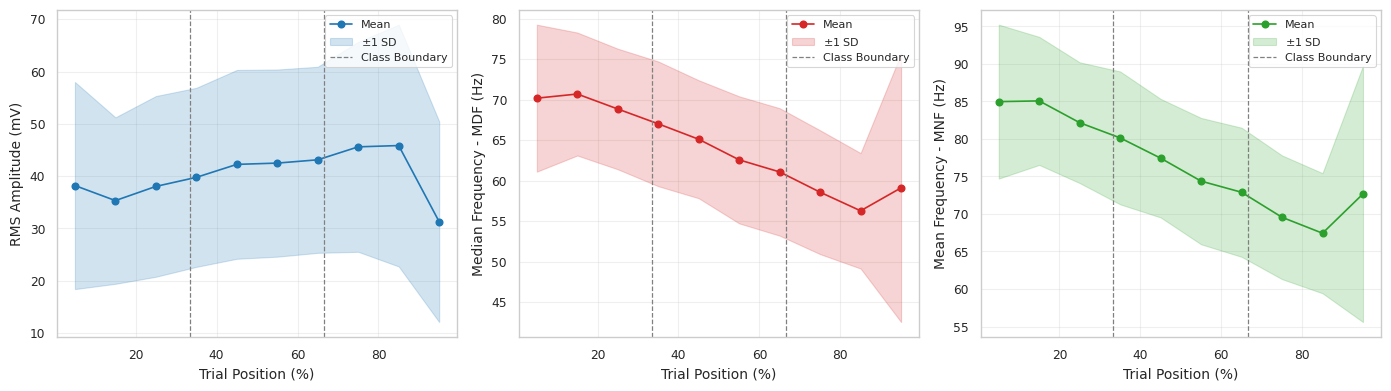


Figura guardada en: /content/drive/MyDrive/EMG_RAW data_procesada/figura_trayectorias.png


In [137]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# === AUTOCONTENIDO: funciona sin ejecutar el Bloque 10 antes ===
KEY = ["sujeto", "repeticion", "lado"]
ruta_salida = "/content/drive/MyDrive/EMG_RAW data_procesada"
ruta_csv    = os.path.join(ruta_salida, "features_dataset_bilateral.csv")

# Cargar df o reusar el que ya esté en memoria, asegurando que tenga 'reposo'
if ('df' not in globals()) or (not isinstance(df, pd.DataFrame)) or ('reposo' not in df.columns):
    print("Cargando df desde CSV y calculando 'reposo'...")
    assert os.path.isfile(ruta_csv), f"NO existe: {ruta_csv}"

    df = pd.read_csv(ruta_csv)

    def reposo_extremos(x):
        act = (x > 0.30 * np.median(x)).values
        i0, i1 = np.argmax(act), len(act) - np.argmax(act[::-1])
        r = np.zeros(len(act), bool)
        r[:i0] = True
        r[i1:] = True
        return pd.Series(r, index=x.index)

    df["reposo"] = df.groupby(KEY, group_keys=False)["RMS"].apply(reposo_extremos)
    print(f"df cargado: {df.shape} | ventanas en reposo: {df.reposo.sum()}")
else:
    print(f"Usando df en memoria: {df.shape}")

# === FIGURA ===
print("=" * 70, "\n5. GENERATING TRAJECTORY FIGURE IN ENGLISH")

fig, axs = plt.subplots(1, 3, figsize=(14, 4))
x = np.arange(1, 11) * 10 - 5

df["idx"] = df.groupby(KEY).cumcount()
k = df.groupby(KEY)["label"].transform(lambda s: (s == 0).sum())
n = df.groupby(KEY)["idx"].transform("size")
rec = (df.groupby(KEY)["label"].transform(lambda s: (s == 2).sum()) < k) & df.RMS_ratio_dr_iz.notna()
df["pos"] = df.idx / np.where(rec, 3 * k + 1, n)
df["decil"] = pd.cut(df.pos, np.linspace(0, 1, 11), include_lowest=True, labels=range(1, 11))

features_config = [
    ("RMS", "RMS Amplitude (mV)", "tab:blue"),
    ("MDF", "Median Frequency - MDF (Hz)", "tab:red"),
    ("MNF", "Mean Frequency - MNF (Hz)", "tab:green")
]

for ax, (f, label_y, color) in zip(axs, features_config):
    a = df[~df.reposo]
    por_sujeto = a.groupby(["sujeto", "decil"], observed=True)[f].mean().unstack("decil")
    mu, sd = por_sujeto.mean(), por_sujeto.std()

    ax.plot(x, mu.values, color=color, marker="o", label="Mean")
    ax.fill_between(x, (mu - sd).values, (mu + sd).values, color=color, alpha=0.2, label=r"$\pm 1$ SD")

    for i, v in enumerate([100 / 3, 200 / 3]):
        bound_label = "Class Boundary" if i == 0 else None
        ax.axvline(v, color="gray", ls="--", lw=0.9, label=bound_label)

    ax.set_xlabel("Trial Position (%)", fontsize=10)
    ax.set_ylabel(label_y, fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", fontsize=8, framealpha=0.8)

plt.tight_layout()
out_fig = os.path.join(ruta_salida, "figura_trayectorias.png")
plt.savefig(out_fig, dpi=300)
plt.show()
print(f"\nFigura guardada en: {out_fig}")

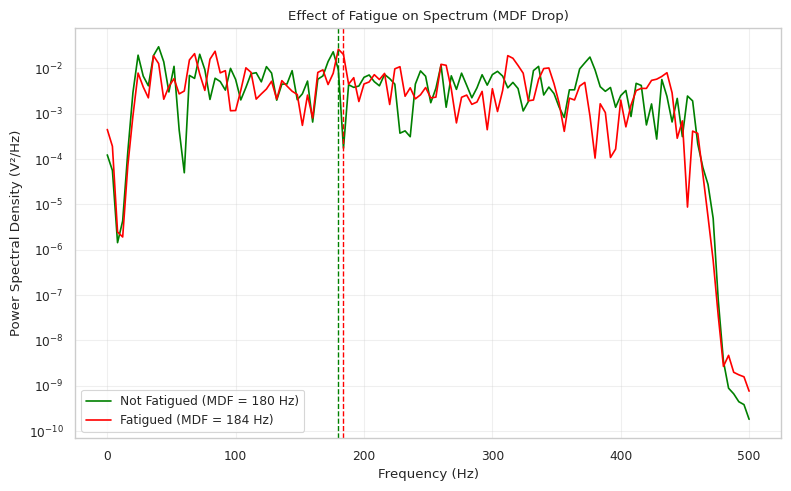

In [138]:
import pandas as pd, numpy as np, scipy.signal as signal
import matplotlib.pyplot as plt

f = DATA_RAW / "sujeto1" / "R1_dr_sujeto1.csv"
df = pd.read_csv(f); fs = 1000

# Filter
b,a = signal.butter(4, [20/(fs/2),450/(fs/2)], btype='band')
x = signal.filtfilt(b, a, df['Voltage_mV'].values)
b2,a2 = signal.iirnotch(60/(fs/2), 30.0)
x = signal.filtfilt(b2, a2, x)

# First window (Class 0) vs Last window (Class 2)
win = int(0.25 * fs)
x_no  = x[:win]
x_fat = x[-win:]

def welch_stats(sig):
    f_, psd = signal.welch(sig, fs=fs, nperseg=min(len(sig),256))
    cum = np.cumsum(psd); mdf = f_[np.where(cum >= cum[-1]/2)[0][0]]
    return f_, psd, mdf

f_n, p_n, mdf_n = welch_stats(x_no)
f_f, p_f, mdf_f = welch_stats(x_fat)

plt.figure(figsize=(8,5))
plt.semilogy(f_n, p_n, color='green', label=f'Not Fatigued (MDF = {mdf_n:.0f} Hz)')
plt.semilogy(f_f, p_f, color='red', label=f'Fatigued (MDF = {mdf_f:.0f} Hz)')
plt.axvline(mdf_n, color='green', ls='--', lw=1)
plt.axvline(mdf_f, color='red', ls='--', lw=1)
plt.xlabel('Frequency (Hz)'); plt.ylabel('Power Spectral Density (V²/Hz)')
plt.title('Effect of Fatigue on Spectrum (MDF Drop)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig('fig3_psd_mdf.png', dpi=200); plt.show()

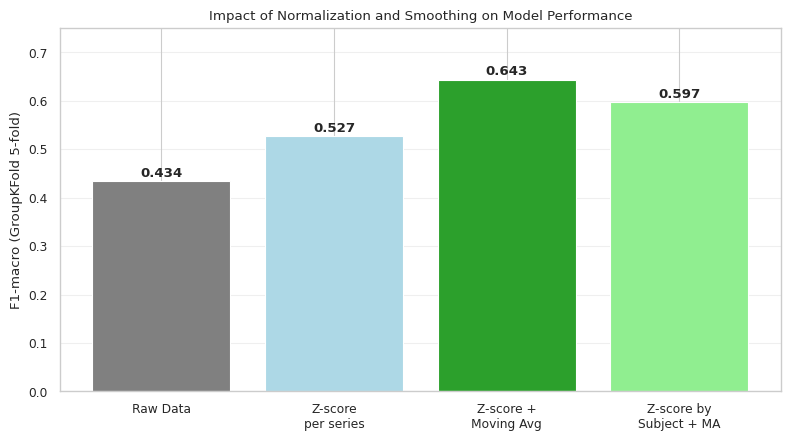

In [139]:
import matplotlib.pyplot as plt

labels = ["Raw Data", "Z-score\nper series", "Z-score +\nMoving Avg", "Z-score by\nSubject + MA"]
f1_scores = [0.434, 0.527, 0.643, 0.597]
colors = ["gray", "lightblue", "tab:green", "lightgreen"]

plt.figure(figsize=(8, 4.5))
bars = plt.bar(labels, f1_scores, color=colors)
for b, v in zip(bars, f1_scores):
    plt.text(b.get_x()+b.get_width()/2, v+0.01, f"{v:.3f}", ha='center', fontweight='bold')

plt.ylim(0, 0.75)
plt.ylabel("F1-macro (GroupKFold 5-fold)")
plt.title("Impact of Normalization and Smoothing on Model Performance")
plt.grid(axis='y', alpha=0.3); plt.tight_layout()
plt.savefig('fig6_f1_results.png', dpi=200); plt.show()

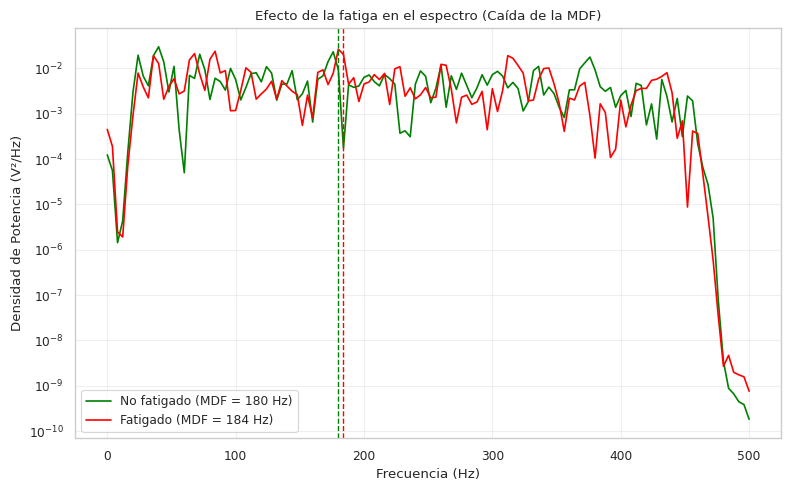

In [140]:
import pandas as pd, numpy as np, scipy.signal as signal
import matplotlib.pyplot as plt

# Usamos la misma señal de antes
f = DATA_RAW / "sujeto1" / "R1_dr_sujeto1.csv"
df = pd.read_csv(f); fs = 1000

# Filtramos la señal completa primero
b,a = signal.butter(4, [20/(fs/2),450/(fs/2)], btype='band')
x = signal.filtfilt(b, a, df['Voltage_mV'].values)
b2,a2 = signal.iirnotch(60/(fs/2), 30.0)
x = signal.filtfilt(b2, a2, x)

# Tomamos una ventana del inicio (Clase 0) y una del final (Clase 2)
win = int(0.25 * fs)
x_no  = x[:win]          # Primeros 250 ms
x_fat = x[-win:]         # Últimos 250 ms

def welch_stats(sig):
    f_, psd = signal.welch(sig, fs=fs, nperseg=min(len(sig),256))
    cum = np.cumsum(psd); mdf = f_[np.where(cum >= cum[-1]/2)[0][0]]
    return f_, psd, mdf

f_n, p_n, mdf_n = welch_stats(x_no)
f_f, p_f, mdf_f = welch_stats(x_fat)

plt.figure(figsize=(8,5))
plt.semilogy(f_n, p_n, color='green', label=f'No fatigado (MDF = {mdf_n:.0f} Hz)')
plt.semilogy(f_f, p_f, color='red', label=f'Fatigado (MDF = {mdf_f:.0f} Hz)')
plt.axvline(mdf_n, color='green', ls='--', lw=1)
plt.axvline(mdf_f, color='red', ls='--', lw=1)
plt.xlabel('Frecuencia (Hz)'); plt.ylabel('Densidad de Potencia (V²/Hz)')
plt.title('Efecto de la fatiga en el espectro (Caída de la MDF)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig('fig2a_psd_mdf.png', dpi=200); plt.show()

In [141]:
import shutil
from pathlib import Path

# Ruta donde está el archivo originalmente en tu Drive
archivo_drive = Path("/content/drive/MyDrive/EMG_RAW data_procesada/features_dataset_bilateral.csv")

# Ruta donde lo espera el código
archivo_destino = DATA_PROCESSED / "features_dataset_bilateral.csv"

if archivo_drive.exists():
    shutil.copy(archivo_drive, archivo_destino)
    print(f"¡Archivo copiado exitosamente a: {archivo_destino}!")
else:
    print("No lo encontré en el Drive. ¿Seguro que ya corriste el procesamiento antes?")

¡Archivo copiado exitosamente a: /content/data/processed/features_dataset_bilateral.csv!


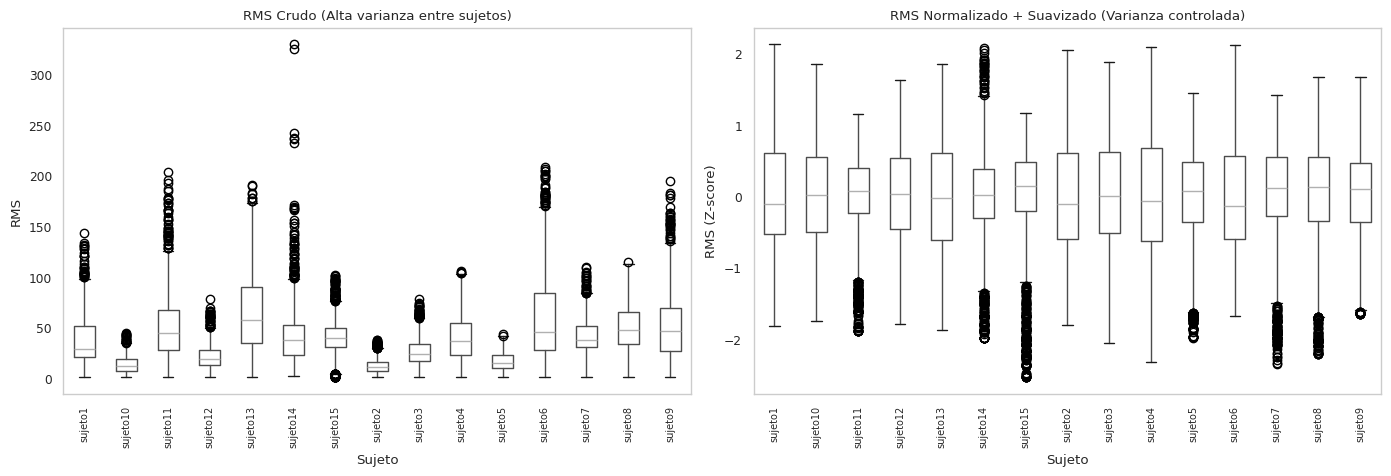

In [142]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

# Cargar el dataset generado
df_b = pd.read_csv(DATA_PROCESSED / "features_dataset_bilateral.csv")
KEY = ["sujeto","repeticion","lado"]

# Hacemos una copia para normalizar
z = df_b.copy()
g = z.groupby(KEY)["RMS"]
# Z-score
z["RMS_norm"] = (z["RMS"] - g.transform("mean")) / g.transform("std")
# Media móvil
z["RMS_norm"] = z.groupby(KEY)["RMS_norm"].transform(lambda s: s.rolling(10, min_periods=1).mean())

# Graficar
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
df_b.boxplot(column="RMS", by="sujeto", ax=axs[0], grid=False)
axs[0].set_title("RMS Crudo (Alta varianza entre sujetos)"); axs[0].set_xlabel("Sujeto")
axs[0].tick_params(axis='x', rotation=90, labelsize=7); axs[0].set_ylabel("RMS")

z.boxplot(column="RMS_norm", by="sujeto", ax=axs[1], grid=False)
axs[1].set_title("RMS Normalizado + Suavizado (Varianza controlada)"); axs[1].set_xlabel("Sujeto")
axs[1].tick_params(axis='x', rotation=90, labelsize=7); axs[1].set_ylabel("RMS (Z-score)")

fig.suptitle(''); plt.tight_layout()
plt.savefig('fig3a_normalizacion.png', dpi=200); plt.show()

PRUEBAS ADICIONALES

In [143]:
import os
import sys
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_validate

# === RUTA CORREGIDA PARA COLAB ===
RUTA = "/content/drive/MyDrive/EMG_RAW data_procesada/features_dataset_bilateral.csv"
assert os.path.isfile(RUTA), f"NO existe: {RUTA}"

KEY = ["sujeto", "repeticion", "lado"]
F = ["RMS", "MAV", "WL", "MDF", "MNF"]
STEP = 0.125
df = pd.read_csv(RUTA)


def reposo_extremos(x):
    act = (x > 0.30 * np.median(x)).values
    i0, i1 = np.argmax(act), len(act) - np.argmax(act[::-1])
    r = np.zeros(len(act), bool)
    r[:i0] = True
    r[i1:] = True
    return pd.Series(r, index=x.index)


df["reposo"] = df.groupby(KEY, group_keys=False)["RMS"].apply(reposo_extremos)
df["idx"] = df.groupby(KEY).cumcount()
k = df.groupby(KEY)["label"].transform(lambda s: (s == 0).sum())
n = df.groupby(KEY)["idx"].transform("size")
rec = (df.groupby(KEY)["label"].transform(lambda s: (s == 2).sum()) < k) & df.RMS_ratio_dr_iz.notna()
df["pos"] = df.idx / np.where(rec, 3 * k + 1, n)

print("=" * 70, "\nA. EFECTO DE LA NORMALIZACION Z-SCORE (RF 100 arboles, prof. 15, class_weight=balanced,")
print("   GroupKFold de 5 pliegues por sujeto REAL)")
rf = RandomForestClassifier(n_estimators=100, max_depth=15, class_weight="balanced", random_state=42, n_jobs=-1)


def ev(X, nombre, y=df.label, groups=df.sujeto, rf=rf, k=5):
    r = cross_validate(rf, X, y, groups=groups, cv=GroupKFold(k), scoring=["accuracy", "f1_macro"])
    print("%-58s exactitud=%.3f  F1 macro=%.3f" % (nombre, r["test_accuracy"].mean(), r["test_f1_macro"].mean()), flush=True)


def z(d, by):
    g = d.groupby(by)[F]
    return (d[F] - g.transform("mean")) / g.transform("std")


def media_movil(Z, d, w=10):
    return Z.groupby([d[c] for c in KEY]).rolling(w, min_periods=1).mean() \
            .reset_index(level=[0, 1, 2], drop=True).sort_index()


ev(df[F], "1. caracteristicas crudas")
Zs = z(df, KEY)
ev(Zs, "2. z-score por SERIE (usa el archivo completo)")
ev(media_movil(Zs, df), "3. z por serie + media movil de 10 ventanas")
Zsub = z(df, ["sujeto"])
ev(Zsub, "4. z-score por SUJETO")
ev(media_movil(Zsub, df), "5. z por sujeto + media movil de 10 ventanas")

print("=" * 70, "\nB. SIMULACION: copias 'suavizada' e 'interpolada' tratadas como sujetos distintos")
print("   (aproximacion del esquema descrito en la Seccion 5.3; NO es el codigo del equipo)")
rf2 = RandomForestClassifier(n_estimators=40, max_depth=12, class_weight="balanced", random_state=42, n_jobs=-1)


def copia(d, modo):
    d = d.copy()
    g = d.groupby(KEY)[F]
    if modo == "suav":
        d[F] = g.transform(lambda s: s.rolling(5, center=True, min_periods=1).mean())
    else:
        d[F] = g.transform(lambda s: (s + s.shift(-1)).div(2).fillna(s))
    return d


def pipeline(d):
    return media_movil(z(d, KEY), d)


sm, it = copia(df, "suav"), copia(df, "interp")
real = pd.concat([df.sujeto, df.sujeto, df.sujeto], ignore_index=True)
df2, sm["sujeto"], it["sujeto"] = df.copy(), df.sujeto + "_suav", df.sujeto + "_interp"
aug = pd.concat([df2, sm, it], ignore_index=True)
X = pd.concat([pipeline(df), pipeline(copia(df, "suav")), pipeline(copia(df, "interp"))], ignore_index=True)
print("filas aumentadas: %d | ids: %d (= 3 x %d)" % (len(aug), aug.sujeto.nunique(), df.sujeto.nunique()))
ev(X, "45 ids (cada copia es un 'sujeto')", y=aug.label, groups=aug.sujeto, rf=rf2)
ev(X, "15 sujetos reales (las 3 copias juntas)", y=aug.label, groups=real, rf=rf2)

print("=" * 70, "\nC. PERIODICIDAD DEL RMS DENTRO DE CADA SERIE (ventanas activas)")
per = []
for _, s in df.groupby(KEY):
    x = s.loc[~s.reposo, "RMS"].values
    if len(x) < 64:
        continue
    x = x - np.polyval(np.polyfit(np.arange(len(x)), x, 1), np.arange(len(x)))
    P = np.abs(np.fft.rfft(x * np.hanning(len(x)))) ** 2
    fr = np.fft.rfftfreq(len(x), STEP)
    m = (fr >= 1 / 8) & (fr <= 1 / 2)
    per.append(1 / fr[m][np.argmax(P[m])])
per = np.array(per)
print("series: %d | periodo dominante (s): mediana %.2f, IQR %.2f-%.2f | entre 2 y 4 s: %.1f%%" %
      (len(per), np.median(per), *np.percentile(per, [25, 75]), 100 * ((per >= 2) & (per <= 4)).mean()))

print("=" * 70, "\nD. SENSIBILIDAD / VARIABILIDAD (analogo, no identico, al indice de Rogers y MacIsaac)")
act = df[~df.reposo]
filas = []
for _, s in act.groupby(KEY):
    if len(s) >= 20:
        filas.append({f: np.polyfit(s.pos, s[f] / s[f].mean(), 1)[0] for f in F})
sl = pd.DataFrame(filas)
esperado = {"RMS": 1, "MAV": 1, "WL": 1, "MDF": -1, "MNF": -1}
tab = pd.DataFrame({"pendiente_media": sl.mean(), "DE_entre_series": sl.std(),
                    "|media|/DE": sl.mean().abs() / sl.std(),
                    "%_series_con_signo_esperado": [100 * (np.sign(sl[f]) == esperado[f]).mean() for f in F]})
print("series:", len(sl))
print(tab.round(3).to_string())

print("=" * 70, "\nE. IMPACTO DE EXCLUIR LOS 5 TRIALS DE LA SECCION 2.3 (S09 izq R0/R0_1 y S14 der R3-R5)")
excl = ((df.sujeto == "sujeto9") & (df.lado == "izquierda")) | \
       ((df.sujeto == "sujeto14") & (df.lado == "derecha") & df.repeticion.isin(["R3", "R4", "R5"]))
print("ventanas en trials excluidos: %d (%.1f%%) en %d series" %
      (excl.sum(), 100 * excl.mean(), df[excl].groupby(KEY).ngroups))
c = df[~excl].copy()
vc = c.label.value_counts().sort_index()
print("restantes: %d | clases: %s | %%: %s" % (len(c), vc.to_dict(), (100 * vc / len(c)).round(2).to_dict()))
cont = (c.sujeto == "sujeto14") & c.repeticion.isin(["R3", "R4", "R5"]) & (c.lado == "izquierda")
print("filas cuyo valor bilateral venia de una pierna excluida (S14 izq R3-R5): %d" % cont.sum())
a = c[~c.reposo]
for f in ["RMS", "MDF", "MNF", "WL"]:
    m = a.groupby(KEY + ["label"])[f].mean().unstack("label")
    d = (m[2] - m[0]).dropna()
    print("%s: cambio mediano %.1f%%, p=%.2g, n=%d series" % (f, 100 * (m[2] / m[0] - 1).median(), stats.wilcoxon(d).pvalue, len(d)))
print("filas totales usadas por el modelo del equipo segun la Seccion 5.3: 93,063 = 3 x %d" % len(df))

A. EFECTO DE LA NORMALIZACION Z-SCORE (RF 100 arboles, prof. 15, class_weight=balanced,
   GroupKFold de 5 pliegues por sujeto REAL)
1. caracteristicas crudas                                  exactitud=0.450  F1 macro=0.434
2. z-score por SERIE (usa el archivo completo)             exactitud=0.528  F1 macro=0.527
3. z por serie + media movil de 10 ventanas                exactitud=0.642  F1 macro=0.643
4. z-score por SUJETO                                      exactitud=0.510  F1 macro=0.509
5. z por sujeto + media movil de 10 ventanas               exactitud=0.596  F1 macro=0.597
B. SIMULACION: copias 'suavizada' e 'interpolada' tratadas como sujetos distintos
   (aproximacion del esquema descrito en la Seccion 5.3; NO es el codigo del equipo)
filas aumentadas: 93063 | ids: 45 (= 3 x 15)
45 ids (cada copia es un 'sujeto')                         exactitud=0.690  F1 macro=0.690
15 sujetos reales (las 3 copias juntas)                    exactitud=0.645  F1 macro=0.646
C. PERIODICIDAD DE

# Baselines

In [144]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# === CARGA con ruta absoluta ===
ruta_salida = "/content/drive/MyDrive/EMG_RAW data_procesada"
ruta_csv    = os.path.join(ruta_salida, "features_dataset_bilateral.csv")
assert os.path.isfile(ruta_csv), f"NO existe: {ruta_csv}"
df = pd.read_csv(ruta_csv)
print(f"Cargado: {df.shape}\n")

# Extraer características obligatorias para el baseline (Sección 5.1)
X = df[['RMS', 'MDF']].values
y = df['label'].values
groups = df['sujeto'].values

# Modelos base
dummy = DummyClassifier(strategy='most_frequent')
log_reg = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)

logo = LeaveOneGroupOut()

results_dummy = {'acc': [], 'prec': [], 'rec': [], 'f1': []}
results_lr    = {'acc': [], 'prec': [], 'rec': [], 'f1': []}

for fold_i, (train_idx, test_idx) in enumerate(logo.split(X, y, groups), 1):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # Escalado ajustado SOLO en train (sin fuga)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled  = scaler.transform(X_test)

    # Baseline 1: Dummy
    dummy.fit(X_train, y_train)
    y_pred_dummy = dummy.predict(X_test)
    results_dummy['acc'].append(accuracy_score(y_test, y_pred_dummy))
    results_dummy['prec'].append(precision_score(y_test, y_pred_dummy, average='macro', zero_division=0))
    results_dummy['rec'].append(recall_score(y_test, y_pred_dummy, average='macro', zero_division=0))
    results_dummy['f1'].append(f1_score(y_test, y_pred_dummy, average='macro', zero_division=0))

    # Baseline 2: Regresión Logística
    log_reg.fit(X_train_scaled, y_train)
    y_pred_lr = log_reg.predict(X_test_scaled)
    results_lr['acc'].append(accuracy_score(y_test, y_pred_lr))
    results_lr['prec'].append(precision_score(y_test, y_pred_lr, average='macro', zero_division=0))
    results_lr['rec'].append(recall_score(y_test, y_pred_lr, average='macro', zero_division=0))
    results_lr['f1'].append(f1_score(y_test, y_pred_lr, average='macro', zero_division=0))

    print(f"  Fold {fold_i:2d} (test={np.unique(groups[test_idx])[0]}): "
          f"dummy acc={results_dummy['acc'][-1]:.3f} | LR acc={results_lr['acc'][-1]:.3f}", flush=True)


def summarize(res):
    return {k: f"{np.mean(v):.4f} +/- {np.std(v):.4f}" for k, v in res.items()}


print("\n=== Baseline 1: Clase mayoritaria (Dummy) ===")
for k, v in summarize(results_dummy).items():
    print(f"  {k}: {v}")

print("\n=== Baseline 2: Regresión Logística (RMS, MDF) ===")
for k, v in summarize(results_lr).items():
    print(f"  {k}: {v}")

Cargado: (31021, 12)

  Fold  1 (test=sujeto1): dummy acc=0.348 | LR acc=0.396
  Fold  2 (test=sujeto10): dummy acc=0.368 | LR acc=0.356
  Fold  3 (test=sujeto11): dummy acc=0.365 | LR acc=0.376
  Fold  4 (test=sujeto12): dummy acc=0.385 | LR acc=0.416
  Fold  5 (test=sujeto13): dummy acc=0.374 | LR acc=0.420
  Fold  6 (test=sujeto14): dummy acc=0.362 | LR acc=0.424
  Fold  7 (test=sujeto15): dummy acc=0.347 | LR acc=0.430
  Fold  8 (test=sujeto2): dummy acc=0.357 | LR acc=0.449
  Fold  9 (test=sujeto3): dummy acc=0.393 | LR acc=0.405
  Fold 10 (test=sujeto4): dummy acc=0.361 | LR acc=0.396
  Fold 11 (test=sujeto5): dummy acc=0.359 | LR acc=0.476
  Fold 12 (test=sujeto6): dummy acc=0.358 | LR acc=0.388
  Fold 13 (test=sujeto7): dummy acc=0.333 | LR acc=0.365
  Fold 14 (test=sujeto8): dummy acc=0.339 | LR acc=0.380
  Fold 15 (test=sujeto9): dummy acc=0.332 | LR acc=0.375

=== Baseline 1: Clase mayoritaria (Dummy) ===
  acc: 0.3587 +/- 0.0168
  prec: 0.1196 +/- 0.0056
  rec: 0.3333 +/- 0

# Base de datos

In [145]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d

# === RUTAS ABSOLUTAS (Drive) ===
ruta_salida = "/content/drive/MyDrive/EMG_RAW data_procesada"
ruta_csv    = os.path.join(ruta_salida, "features_dataset_bilateral.csv")
output_dir  = os.path.join(ruta_salida, "graficas_todos_los_sujetos")

# Verificar que el CSV existe antes de leerlo
assert os.path.isfile(ruta_csv), (
    f"NO existe: {ruta_csv}\n"
    f"Contenido de la carpeta:\n"
    f"{os.listdir(ruta_salida) if os.path.isdir(ruta_salida) else 'la carpeta tampoco existe'}\n"
    "¿Corriste el Bloque 4 y terminó con 'Dataset bilateral guardado'?"
)

# Crear carpeta de salida
os.makedirs(output_dir, exist_ok=True)

# Cargar dataset
df = pd.read_csv(ruta_csv)
print(f"Cargado: {ruta_csv}  |  Shape: {df.shape}")
print(f"Gráficas se guardarán en: {output_dir}\n")

# Agrupar por sujeto, repetición y lado
grupos = df.groupby(['sujeto', 'repeticion', 'lado'])
bg_color = '#E8E8F2'

n_graficas = 0
for (sujeto, repeticion, lado), datos_grupo in grupos:
    datos = datos_grupo.sort_values('time_s')
    tiempo = datos['time_s'].values
    senal  = datos['RMS'].values

    # Suavizado gaussiano
    senal_suavizada = gaussian_filter1d(senal, sigma=2)

    # Picos sobre la señal suavizada
    picos, _ = find_peaks(senal_suavizada, distance=5, prominence=0.3)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    fig.patch.set_facecolor(bg_color)
    fig.suptitle(f'Sujeto: {sujeto} | Serie: {repeticion} | Lado: {lado.capitalize()}',
                 fontsize=14, fontweight='bold')

    # Subplot 1: señal original
    ax1.plot(tiempo, senal, color='#5c6b8c', linewidth=1.5)
    ax1.set_ylabel('Amplitud (RMS)')
    ax1.set_title('Señal Original (RMS)', loc='left', fontsize=10)
    ax1.set_facecolor(bg_color)
    ax1.grid(True, color='white', linestyle='-', linewidth=1.5)

    # Subplot 2: envolvente suavizada + picos
    ax2.plot(tiempo, senal_suavizada, color='#5c6b8c', linewidth=1.5, label='Envolvente suavizada')
    ax2.plot(tiempo[picos], senal_suavizada[picos], 'o', color='#d9534f',
             markersize=4, label=f'Picos (n={len(picos)})')
    ax2.set_xlabel('Tiempo (s)')
    ax2.set_ylabel('Amplitud Suavizada')
    ax2.set_title('Señal Suavizada', loc='left', fontsize=10)
    ax2.set_facecolor(bg_color)
    ax2.grid(True, color='white', linestyle='-', linewidth=1.5)
    ax2.legend(loc='upper right')

    plt.tight_layout()

    nombre_archivo = os.path.join(output_dir, f"{sujeto}_{repeticion}_{lado}.png")
    plt.savefig(nombre_archivo, dpi=150, facecolor=fig.get_facecolor())
    plt.close()
    n_graficas += 1

    if n_graficas % 30 == 0:
        print(f"  ... {n_graficas} gráficas generadas", flush=True)

print(f"\n¡Proceso terminado! {n_graficas} imágenes guardadas en '{output_dir}'.")

Cargado: /content/drive/MyDrive/EMG_RAW data_procesada/features_dataset_bilateral.csv  |  Shape: (31021, 12)
Gráficas se guardarán en: /content/drive/MyDrive/EMG_RAW data_procesada/graficas_todos_los_sujetos

  ... 30 gráficas generadas
  ... 60 gráficas generadas
  ... 90 gráficas generadas
  ... 120 gráficas generadas

¡Proceso terminado! 139 imágenes guardadas en '/content/drive/MyDrive/EMG_RAW data_procesada/graficas_todos_los_sujetos'.


In [146]:
import os
from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# 1. Localizar la carpeta donde está features_dataset_bilateral.csv
# ------------------------------------------------------------
candidatos = [
    Path("/content/drive/MyDrive/EMG_RAW data_procesada"),  # Colab + Drive (tu caso actual)
    Path("outputs"),                                        # refactor local
    Path("/content/emg-fatigue-project/outputs"),           # Colab + repo clonado
    Path.cwd(),                                             # por si acaso
]

RUTA_SALIDA = None
for c in candidatos:
    if (c / "features_dataset_bilateral.csv").exists():
        RUTA_SALIDA = c
        break

if RUTA_SALIDA is None:
    # No lo encontró: imprime qué hay para diagnosticar
    print("❌ No se encontró features_dataset_bilateral.csv en ninguna de estas rutas:")
    for c in candidatos:
        print(f"   {c}  ->  existe={c.exists()}")
        if c.exists():
            try:
                print(f"      contenido: {os.listdir(c)[:10]}")
            except Exception as e:
                print(f"      error listando: {e}")
    raise FileNotFoundError(
        "Corre primero el pipeline hasta la celda que guarda features_dataset_bilateral.csv, "
        "o ajusta 'candidatos' a la carpeta correcta."
    )

print(f"✅ RUTA_SALIDA = {RUTA_SALIDA}")

# ------------------------------------------------------------
# 2. Cargar y aplicar exclusiones (versión corregida con isin)
# ------------------------------------------------------------
ruta_csv = RUTA_SALIDA / "features_dataset_bilateral.csv"
df = pd.read_csv(ruta_csv)
filas_originales = len(df)

lado_norm = df['lado'].astype(str).str.lower().str.strip()
rep_norm  = df['repeticion'].astype(str).str.upper().str.strip()

es_izq = lado_norm.str.startswith('iz')
es_der = lado_norm.str.startswith('d')

excluir_s14 = (df['sujeto'] == 'sujeto14') & es_izq & rep_norm.isin(['R4', 'R5'])
excluir_s15 = (df['sujeto'] == 'sujeto15') & es_der & rep_norm.isin(['R1', 'R2', 'R3'])
filas_a_eliminar = excluir_s14 | excluir_s15

print("\nFilas que se eliminarán por (sujeto, rep, lado):")
print(df.loc[filas_a_eliminar].groupby(['sujeto', 'repeticion', 'lado']).size())

# ------------------------------------------------------------
# 3. Dataset limpio + guardado en RUTA_SALIDA
# ------------------------------------------------------------
df_limpio = df.loc[~filas_a_eliminar].copy()
nuevo_path = RUTA_SALIDA / "features_dataset_limpio.csv"
df_limpio.to_csv(nuevo_path, index=False)

print(f"\nDataset original:  {filas_originales} filas.")
print(f"Filas eliminadas:  {int(filas_a_eliminar.sum())} filas.")
print(f"Dataset limpio:    {len(df_limpio)} filas.")
print(f"Guardado en:       {nuevo_path}")

✅ RUTA_SALIDA = /content/drive/MyDrive/EMG_RAW data_procesada

Filas que se eliminarán por (sujeto, rep, lado):
sujeto    repeticion  lado     
sujeto14  R4          izquierda    173
          R5          izquierda    184
sujeto15  R1          derecha      194
          R2          derecha      205
          R3          derecha      209
dtype: int64

Dataset original:  31021 filas.
Filas eliminadas:  965 filas.
Dataset limpio:    30056 filas.
Guardado en:       /content/drive/MyDrive/EMG_RAW data_procesada/features_dataset_limpio.csv


In [147]:
import os
from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# 1. Localizar RUTA_SALIDA (si no está en globals)
# ------------------------------------------------------------
if "RUTA_SALIDA" not in globals() or not Path(RUTA_SALIDA).is_dir():
    candidatos = [
        Path("/content/drive/MyDrive/EMG_RAW data_procesada"),
        Path("outputs"),
        Path("/content/emg-fatigue-project/outputs"),
        Path.cwd(),
    ]
    RUTA_SALIDA = None
    for c in candidatos:
        if (c / "features_dataset_limpio.csv").exists():
            RUTA_SALIDA = c
            break
    if RUTA_SALIDA is None:
        raise FileNotFoundError(
            "No se encontró 'features_dataset_limpio.csv'. "
            "Corre antes la celda de exclusión que lo genera en RUTA_SALIDA."
        )

print(f"✅ RUTA_SALIDA = {RUTA_SALIDA}")

# ------------------------------------------------------------
# 2. Cargar dataset limpio
# ------------------------------------------------------------
ruta_in = RUTA_SALIDA / "features_dataset_limpio.csv"
assert ruta_in.exists(), f"NO existe: {ruta_in}"
df = pd.read_csv(ruta_in)

# ------------------------------------------------------------
# 3. Suavizado
# ------------------------------------------------------------
smooth_cols = ['RMS', 'MAV', 'WL', 'MDF', 'MNF', 'RMS_ratio_dr_iz', 'MDF_diff_dr_iz']

df_new = df.copy()
df_new[smooth_cols] = df_new.groupby(['sujeto', 'repeticion', 'lado'])[smooth_cols].transform(
    lambda x: x.rolling(window=5, min_periods=1).mean()
)

df_new['sujeto'] = df_new['sujeto'].apply(
    lambda s: f"sujeto{int(s.replace('sujeto', '')) + 15}"
)

df_combined = pd.concat([df, df_new], ignore_index=True)

# ------------------------------------------------------------
# 4. Guardar en RUTA_SALIDA (NO en CWD)
# ------------------------------------------------------------
out_path = RUTA_SALIDA / "features_dataset_bilateral_suavizado.csv"
df_combined.to_csv(out_path, index=False)

print(f"Dataset original:                       {df.shape[0]} filas")
print(f"Nuevos datos (sujetos 16-30 suavizados): {df_new.shape[0]} filas")
print(f"Dataset combinado final:                {df_combined.shape[0]} filas")
print(f"Guardado en:                            {out_path}")

✅ RUTA_SALIDA = /content/drive/MyDrive/EMG_RAW data_procesada
Dataset original:                       30056 filas
Nuevos datos (sujetos 16-30 suavizados): 30056 filas
Dataset combinado final:                60112 filas
Guardado en:                            /content/drive/MyDrive/EMG_RAW data_procesada/features_dataset_bilateral_suavizado.csv


In [148]:
from pathlib import Path
import os

# Detectar RUTA_SALIDA
candidatos = [
    Path("/content/drive/MyDrive/EMG_RAW data_procesada"),
    Path("outputs"),
    Path("/content/emg-fatigue-project/outputs"),
    Path.cwd(),
]
RUTA_SALIDA = None
for c in candidatos:
    if (c / "features_dataset_bilateral_suavizado.csv").exists():
        RUTA_SALIDA = c
        break

if RUTA_SALIDA is None:
    print("❌ NO existe features_dataset_bilateral_suavizado.csv en:")
    for c in candidatos:
        print(f"   {c}  -> existe={c.exists()}")
        if c.exists():
            print(f"      contenido: {os.listdir(c)[:10]}")
    raise FileNotFoundError(
        "Corre PRIMERO la celda 16 corregida (la del suavizado) antes de este bloque."
    )

print(f"✅ RUTA_SALIDA = {RUTA_SALIDA}")
print(f"✅ archivo existe: {(RUTA_SALIDA / 'features_dataset_bilateral_suavizado.csv').exists()}")

✅ RUTA_SALIDA = /content/drive/MyDrive/EMG_RAW data_procesada
✅ archivo existe: True


In [149]:
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 1. Detectar RUTA_SALIDA si no está definida
# ------------------------------------------------------------
if "RUTA_SALIDA" not in globals() or not Path(RUTA_SALIDA).is_dir():
    candidatos = [
        Path("/content/drive/MyDrive/EMG_RAW data_procesada"),
        Path("outputs"),
        Path("/content/emg-fatigue-project/outputs"),
        Path.cwd(),
    ]
    RUTA_SALIDA = None
    for c in candidatos:
        if (c / "features_dataset_bilateral_suavizado.csv").exists():
            RUTA_SALIDA = c
            break
    if RUTA_SALIDA is None:
        raise FileNotFoundError(
            "No se encontró features_dataset_bilateral_suavizado.csv. "
            "Corre primero la celda 16 corregida (suavizado)."
        )

print(f"✅ RUTA_SALIDA = {RUTA_SALIDA}")

# ------------------------------------------------------------
# 2. Cargar el dataset anterior (sujetos 1-30)
# ------------------------------------------------------------
ruta_in = RUTA_SALIDA / "features_dataset_bilateral_suavizado.csv"
assert ruta_in.exists(), f"NO existe: {ruta_in}"
df_combined = pd.read_csv(ruta_in)

# ------------------------------------------------------------
# 3. Separar 1-15 vs 16-30 e interpolar
# ------------------------------------------------------------
df_raw    = df_combined[df_combined['sujeto'].isin([f'sujeto{i}' for i in range(1, 16)])].reset_index(drop=True)
df_smooth = df_combined[df_combined['sujeto'].isin([f'sujeto{i}' for i in range(16, 31)])].reset_index(drop=True)

# Sanity check: deben ser iguales en longitud (misma cantidad de ventanas)
assert len(df_raw) == len(df_smooth), (
    f"Tamaños distintos: raw={len(df_raw)}, smooth={len(df_smooth)}. "
    "Revisa que la celda 16 haya suavizado sin perder filas."
)

df_interp = df_raw.copy()
num_cols = ['RMS', 'MAV', 'WL', 'MDF', 'MNF', 'RMS_ratio_dr_iz', 'MDF_diff_dr_iz']
df_interp[num_cols] = (df_raw[num_cols] + df_smooth[num_cols]) / 2.0

df_interp['sujeto'] = df_interp['sujeto'].apply(
    lambda s: f"sujeto{int(s.replace('sujeto', '')) + 30}"
)

df_final = pd.concat([df_combined, df_interp], ignore_index=True)

# ------------------------------------------------------------
# 4. Guardar en RUTA_SALIDA (no en CWD)
# ------------------------------------------------------------
out_path = RUTA_SALIDA / "features_dataset_bilateral_interpolado.csv"
df_final.to_csv(out_path, index=False)

print(f"Filas originales + suavizadas:                {df_combined.shape[0]}")
print(f"Filas interpoladas agregadas (sujetos 31-45): {df_interp.shape[0]}")
print(f"Total de filas en el nuevo dataset:           {df_final.shape[0]}")
print(f"Sujetos finales: {len(df_final['sujeto'].unique())} (1-45)")
print(f"Guardado en:                                  {out_path}")

✅ RUTA_SALIDA = /content/drive/MyDrive/EMG_RAW data_procesada
Filas originales + suavizadas:                60112
Filas interpoladas agregadas (sujetos 31-45): 30056
Total de filas en el nuevo dataset:           90168
Sujetos finales: 45 (1-45)
Guardado en:                                  /content/drive/MyDrive/EMG_RAW data_procesada/features_dataset_bilateral_interpolado.csv


Analisis de datos

✅ RUTA_SALIDA = /content/drive/MyDrive/EMG_RAW data_procesada
✅ Cargado: /content/drive/MyDrive/EMG_RAW data_procesada/features_dataset_bilateral_interpolado.csv  shape=(90168, 12)


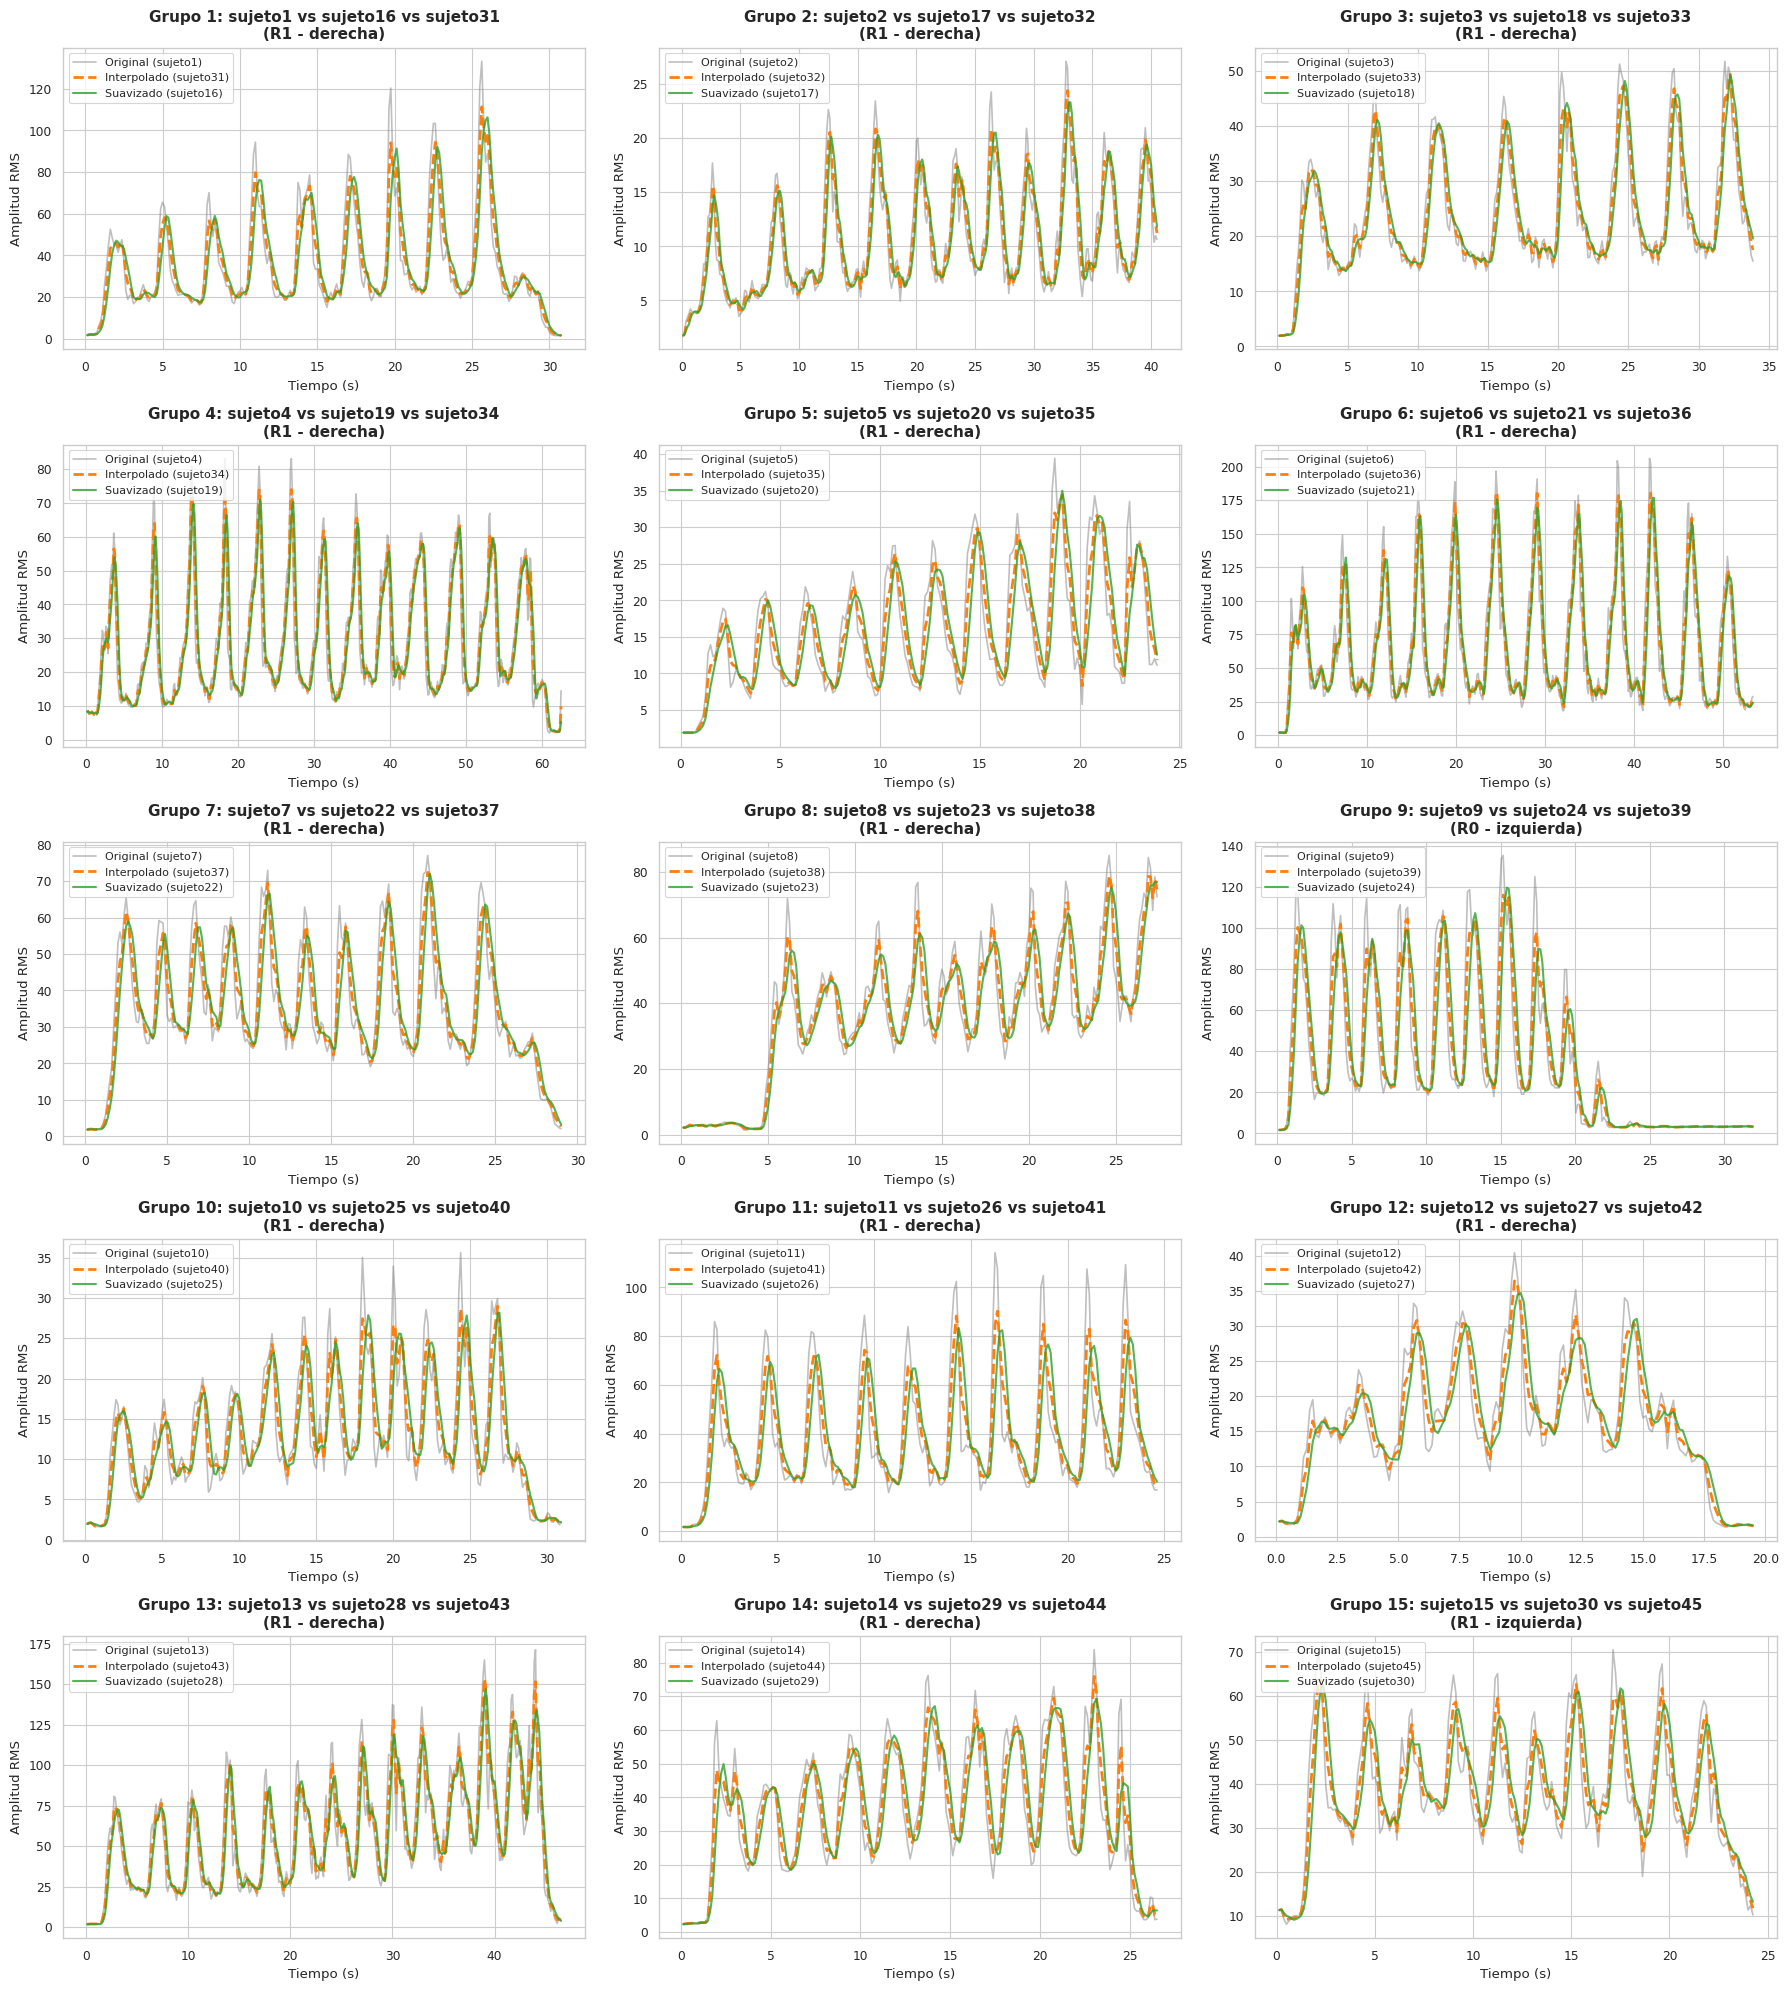

✅ Figura guardada en: /content/drive/MyDrive/EMG_RAW data_procesada/comparacion_tripletas.png

Desviación estándar de RMS (dispersión/ruido) por variante:
 Grupo_Base  Std_Original  Std_Interpolado  Std_Suavizado
          1         23.76            21.80          21.65
          2          7.03             6.60           6.56
          3         13.37            12.59          12.55
          4         21.57            20.40          20.30
          5          8.57             7.62           7.56
          6         41.09            37.37          37.04
          7         20.06            18.30          18.11
          8         24.66            23.10          22.93
          9         36.70            31.80          31.19
         10          8.04             7.32           7.25
         11         33.38            27.08          26.18
         12         12.48            11.46          11.35
         13         37.38            34.58          34.28
         14         25.43        

In [150]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os

# ------------------------------------------------------------
# 1. Detectar RUTA_SALIDA si no está definida
# ------------------------------------------------------------
if "RUTA_SALIDA" not in globals() or not Path(RUTA_SALIDA).is_dir():
    candidatos = [
        Path("/content/drive/MyDrive/EMG_RAW data_procesada"),
        Path("outputs"),
        Path("/content/emg-fatigue-project/outputs"),
        Path.cwd(),
    ]
    RUTA_SALIDA = None
    for c in candidatos:
        if (c / "features_dataset_bilateral_interpolado.csv").exists():
            RUTA_SALIDA = c
            break
    if RUTA_SALIDA is None:
        raise FileNotFoundError(
            "No se encontró features_dataset_bilateral_interpolado.csv. "
            "Corre antes la celda 17 corregida."
        )

print(f"✅ RUTA_SALIDA = {RUTA_SALIDA}")

# ------------------------------------------------------------
# 2. Cargar el dataset
# ------------------------------------------------------------
ruta_csv = RUTA_SALIDA / "features_dataset_bilateral_interpolado.csv"
assert ruta_csv.exists(), f"NO existe: {ruta_csv}"
df = pd.read_csv(ruta_csv)
print(f"✅ Cargado: {ruta_csv}  shape={df.shape}")

# ------------------------------------------------------------
# 3. Figura de tripletas
# ------------------------------------------------------------
sns.set_theme(style="whitegrid", context="paper")
fig, axes = plt.subplots(5, 3, figsize=(18, 20))
axes = axes.flatten()

stats = []

for i in range(1, 16):
    ax = axes[i-1]

    s_orig = f"sujeto{i}"
    s_suav = f"sujeto{i+15}"
    s_intp = f"sujeto{i+30}"

    temp_df = df[df['sujeto'] == s_orig]
    if len(temp_df) == 0:
        continue
    rep  = temp_df['repeticion'].iloc[0]
    lado = temp_df['lado'].iloc[0]

    df_orig = temp_df[(temp_df['repeticion'] == rep) & (temp_df['lado'] == lado)]
    df_suav = df[(df['sujeto'] == s_suav) & (df['repeticion'] == rep) & (df['lado'] == lado)]
    df_intp = df[(df['sujeto'] == s_intp) & (df['repeticion'] == rep) & (df['lado'] == lado)]

    ax.plot(df_orig['time_s'], df_orig['RMS'], label=f'Original ({s_orig})',
            alpha=0.5, color='gray')
    ax.plot(df_intp['time_s'], df_intp['RMS'], label=f'Interpolado ({s_intp})',
            linestyle='--', linewidth=2, color='tab:orange')
    ax.plot(df_suav['time_s'], df_suav['RMS'], label=f'Suavizado ({s_suav})',
            alpha=0.8, linewidth=1.5, color='tab:green')

    ax.set_title(f"Grupo {i}: {s_orig} vs {s_suav} vs {s_intp}\n({rep} - {lado})",
                 fontsize=11, fontweight='bold')
    ax.set_xlabel("Tiempo (s)")
    ax.set_ylabel("Amplitud RMS")
    ax.legend(fontsize=8, loc='upper left')

    std_orig = df[df['sujeto'] == s_orig]['RMS'].std()
    std_suav = df[df['sujeto'] == s_suav]['RMS'].std()
    std_intp = df[df['sujeto'] == s_intp]['RMS'].std()
    stats.append((i, std_orig, std_intp, std_suav))

plt.tight_layout()

# Guardar EN RUTA_SALIDA (no en CWD)
out_fig = RUTA_SALIDA / "comparacion_tripletas.png"
plt.savefig(out_fig, dpi=300, bbox_inches="tight")
plt.show()
print(f"✅ Figura guardada en: {out_fig}")

# ------------------------------------------------------------
# 4. Tabla resumen
# ------------------------------------------------------------
stats_df = pd.DataFrame(stats, columns=['Grupo_Base', 'Std_Original',
                                        'Std_Interpolado', 'Std_Suavizado'])
print("\nDesviación estándar de RMS (dispersión/ruido) por variante:")
print(stats_df.round(2).to_string(index=False))

# Random Forest

--------------------------------------------------
Accuracy Global: 0.7553
F1-Score (Macro): 0.7554
--------------------------------------------------
Reporte por Clases
              precision    recall  f1-score   support

           0       0.81      0.82      0.82      6475
           1       0.68      0.71      0.70      6470
           2       0.79      0.72      0.75      4915

    accuracy                           0.76     17860
   macro avg       0.76      0.75      0.76     17860
weighted avg       0.76      0.76      0.76     17860

--------------------------------------------------


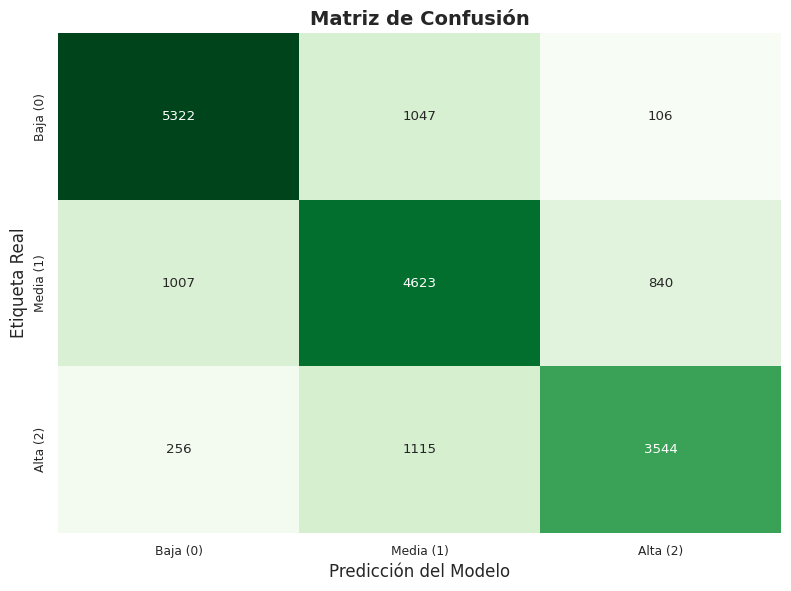

In [151]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

# --- Fix de ruta ---
if "RUTA_SALIDA" not in globals() or not Path(RUTA_SALIDA).is_dir():
    for c in [Path("/content/drive/MyDrive/EMG_RAW data_procesada"),
              Path("outputs"), Path.cwd()]:
        if (c / "features_dataset_bilateral_interpolado.csv").exists():
            RUTA_SALIDA = c
            break
    else:
        raise FileNotFoundError("Corre antes la celda 17 (interpolado).")

# 1. Cargar el dataset
df = pd.read_csv(RUTA_SALIDA / "features_dataset_bilateral_interpolado.csv")   # ← antes: 'features_dataset_bilateral_interpolado.csv'

# Imputar nulos con la mediana
df['RMS_ratio_dr_iz'] = df['RMS_ratio_dr_iz'].fillna(df['RMS_ratio_dr_iz'].median())
df['MDF_diff_dr_iz'] = df['MDF_diff_dr_iz'].fillna(df['MDF_diff_dr_iz'].median())

# Ordenar cronológicamente
df = df.sort_values(['sujeto', 'repeticion', 'lado', 'time_s'])

# 2. Ingeniería de Características
cols_to_norm = ['RMS', 'MAV', 'WL', 'MDF', 'MNF']
for col in cols_to_norm:
    df[f'{col}_z'] = df.groupby(['sujeto', 'lado'])[col].transform(lambda x: (x - x.mean()) / x.std())

for col in ['RMS', 'MDF']:
    df[f'{col}_slope'] = df.groupby(['sujeto', 'repeticion', 'lado'])[col].diff().fillna(0)

for col in ['MDF_z', 'RMS_z']:
    df[f'{col}_roll10'] = df.groupby(['sujeto', 'repeticion', 'lado'])[col].transform(lambda x: x.rolling(10, min_periods=1).mean())

# 3. Separación estricta por sujetos (80% Train / 20% Test)
np.random.seed(42)
random.seed(42)
sujetos = df['sujeto'].unique()
train_sujetos = np.random.choice(sujetos, size=36, replace=False)
test_sujetos = [s for s in sujetos if s not in train_sujetos]

features = ['RMS_ratio_dr_iz', 'MDF_diff_dr_iz'] + [f'{c}_z' for c in cols_to_norm] + ['RMS_slope', 'MDF_slope', 'MDF_z_roll10', 'RMS_z_roll10']

X_train = df[df['sujeto'].isin(train_sujetos)][features]
y_train = df[df['sujeto'].isin(train_sujetos)]['label']
X_test = df[df['sujeto'].isin(test_sujetos)][features]
y_test = df[df['sujeto'].isin(test_sujetos)]['label']

# 4. Entrenar el Random Forest
rf = RandomForestClassifier(n_estimators=150, max_depth=25, class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

# 5. Métricas
accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')
report = classification_report(y_test, y_pred)

print("-" * 50)
print(f"Accuracy Global: {accuracy:.4f}")
print(f"F1-Score (Macro): {macro_f1:.4f}")
print("-" * 50)
print("Reporte por Clases")
print(report)
print("-" * 50)

# 6. Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Baja (0)', 'Media (1)', 'Alta (2)'],
            yticklabels=['Baja (0)', 'Media (1)', 'Alta (2)'])

plt.title('Matriz de Confusión', fontsize=14, fontweight='bold')
plt.xlabel('Predicción del Modelo', fontsize=12)
plt.ylabel('Etiqueta Real', fontsize=12)
plt.tight_layout()

plt.savefig(RUTA_SALIDA / 'confusion_matrix_rf_absolute.png', dpi=300)   # ← antes: 'confusion_matrix_rf_absolute.png'
plt.show()

/tmp/ipykernel_836/578164803.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=nombres_sujetos, y=valores_f1, palette="viridis")


¡Imagen per_subject_f1.png generada con éxito!


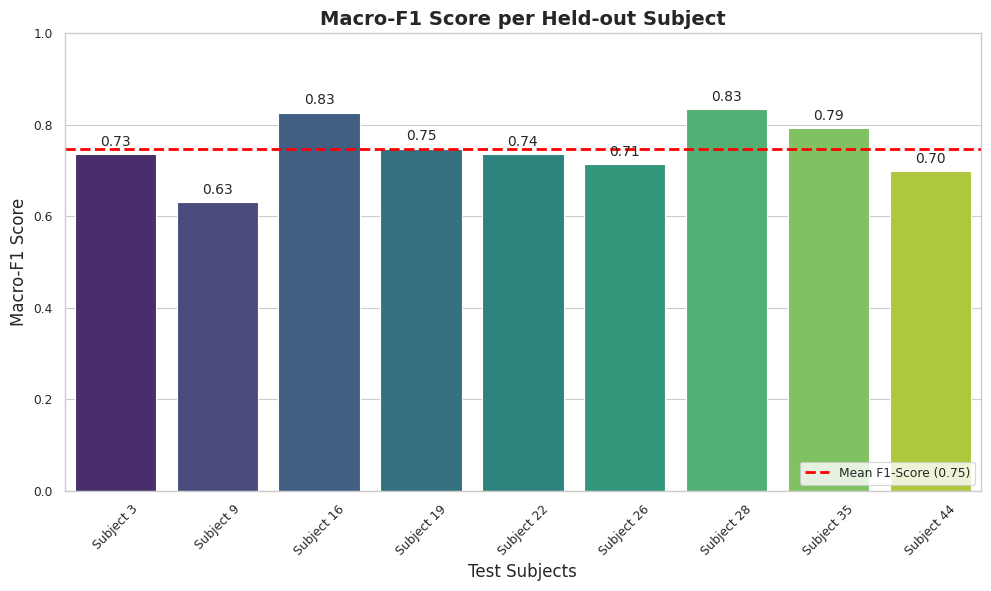

In [152]:
from sklearn.metrics import f1_score

# 1. Calcular F1-Score macro para cada sujeto de prueba
f1_scores = {}
test_sujetos_sorted = sorted(test_sujetos, key=lambda x: int(x.replace('sujeto', '')))

for subj in test_sujetos_sorted:
    X_test_subj = df[df['sujeto'] == subj][features]
    y_test_subj = df[df['sujeto'] == subj]['label']

    y_pred_subj = rf.predict(X_test_subj)
    f1_scores[subj] = f1_score(y_test_subj, y_pred_subj, average='macro')

# 2. Crear la gráfica de barras verticales
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

nombres_sujetos = [s.replace('sujeto', 'Subject ') for s in f1_scores.keys()]
valores_f1 = list(f1_scores.values())
mean_f1 = np.mean(valores_f1)

ax = sns.barplot(x=nombres_sujetos, y=valores_f1, palette="viridis")
plt.axhline(mean_f1, color='red', linestyle='--', linewidth=2, label=f'Mean F1-Score ({mean_f1:.2f})')

plt.ylim(0, 1.0)
plt.title('Macro-F1 Score per Held-out Subject', fontsize=14, fontweight='bold')
plt.ylabel('Macro-F1 Score', fontsize=12)
plt.xlabel('Test Subjects', fontsize=12)
plt.xticks(rotation=45)
plt.legend(loc='lower right')

# Añadir el valor exacto sobre cada barra
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.2f'),
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=10)

plt.tight_layout()
plt.savefig('per_subject_f1.png', dpi=300)
print("¡Imagen per_subject_f1.png generada con éxito!")
plt.show()

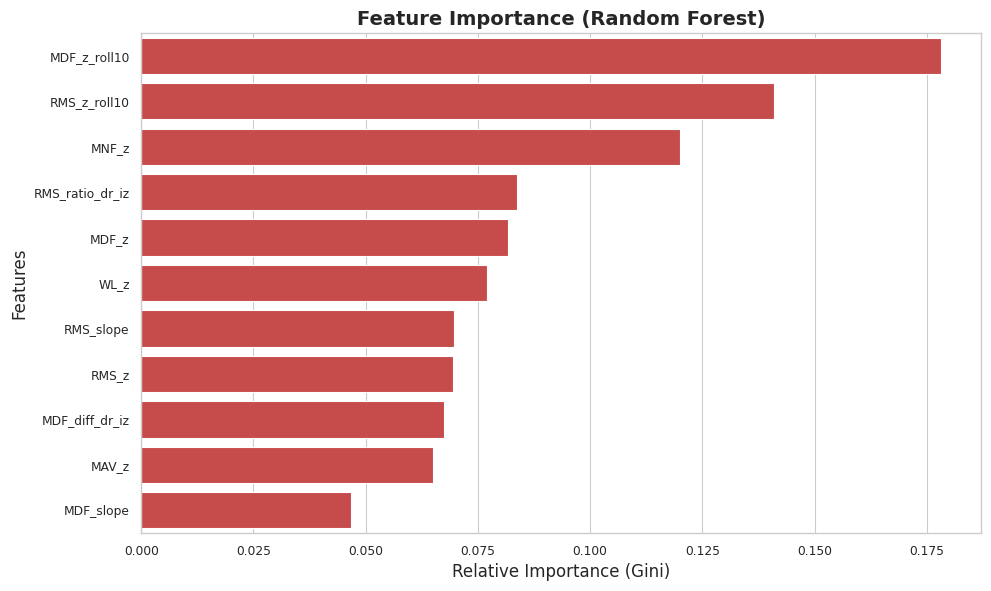

In [153]:

importancias = rf.feature_importances_
indices = np.argsort(importancias)[::-1]
nombres_ordenados = [features[i] for i in indices]
valores_ordenados = importancias[indices]

# Graficar
plt.figure(figsize=(10, 6))
sns.barplot(x=valores_ordenados, y=nombres_ordenados, color="#DA3737")

plt.title('Feature Importance (Random Forest)', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance (Gini)', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()

# Guardar la imagen para Overleaf
plt.savefig('feature_importance1.png', dpi=300)
plt.show()

In [166]:
import joblib

# Guardar el modelo entrenado en un archivo .pkl
joblib.dump(rf, 'modelo_fatiga_rf.pkl')
print("¡Modelo guardado exitosamente como 'modelo_fatiga_rf.pkl'!")

¡Modelo guardado exitosamente como 'modelo_fatiga_rf.pkl'!


# Tratamiento de la señal de prueba

In [155]:
import os
from pathlib import Path

RAW_DIR = Path("/content/drive/MyDrive/raw")
print(f"Existe: {RAW_DIR.is_dir()}")
if RAW_DIR.is_dir():
    for f in sorted(RAW_DIR.iterdir()):
        kind = "DIR " if f.is_dir() else "file"
        size = f.stat().st_size if f.is_file() else 0
        print(f"  [{kind}] {f.name}  ({size} bytes)")

Existe: True
  [file] P11_set01_dr.csv  (976784 bytes)
  [file] P11_set01_iz.csv  (773650 bytes)
  [file] P11_set02_dr.csv  (745186 bytes)
  [file] P11_set02_iz.csv  (714684 bytes)
  [file] P11_set03_dr.csv  (664193 bytes)
  [file] P11_set03_iz.csv  (613937 bytes)
  [file] P11_set04_dr.csv  (603586 bytes)
  [file] P11_set04_iz.csv  (589688 bytes)
  [file] P11_set05_dr.csv  (538781 bytes)
  [file] P11_set05_iz.csv  (537128 bytes)
  [file] P12_set01_dr.csv  (715148 bytes)
  [file] P12_set01_iz.csv  (691618 bytes)
  [file] P12_set02_dr.csv  (764251 bytes)
  [file] P12_set02_iz.csv  (663939 bytes)
  [file] P12_set03_dr.csv  (775506 bytes)
  [file] P12_set03_iz.csv  (708775 bytes)
  [file] P12_set04_dr.csv  (750793 bytes)
  [file] P12_set04_iz.csv  (762161 bytes)
  [file] P12_set05_dr.csv  (658049 bytes)
  [file] P12_set05_iz.csv  (648737 bytes)


In [163]:
import pandas as pd
import numpy as np
from scipy.signal import welch, butter, filtfilt, iirnotch
from pathlib import Path

print("Iniciando extracción de características...")

# --- Fix de ruta ---
RUTA_PACIENTE = Path("/content/drive/MyDrive/raw/P11_set01_dr.csv")

if not RUTA_PACIENTE.exists():
    raise FileNotFoundError(f"NO existe: {RUTA_PACIENTE}")

print(f"✅ Usando: {RUTA_PACIENTE}")

# 1. Cargar la señal cruda
df_raw = pd.read_csv(RUTA_PACIENTE)

# 2. Configuración
fs = 1000
window_length = 250  # Ya corregido a 250ms

# --- 3. NUEVO: FUNCIÓN DE FILTRADO (Idéntica a la del entrenamiento) ---
def aplicar_filtros_emg(data, fs=1000):
    # Filtro Pasa-Banda (20 - 450 Hz)
    b_bp, a_bp = butter(4, [20.0/(fs/2), 450.0/(fs/2)], btype='band')
    filtered = filtfilt(b_bp, a_bp, data)
    # Filtro Notch (60 Hz para ruido eléctrico)
    b_notch, a_notch = iirnotch(60.0/(fs/2), 30.0)
    filtered = filtfilt(b_notch, a_notch, filtered)
    return filtered

print("Aplicando filtros...")
señal_filtrada = aplicar_filtros_emg(df_raw['Voltage_mV'].values, fs)

caracteristicas = []

# 4. Procesar la señal FILTRADA por ventanas
for i in range(0, len(señal_filtrada), window_length):
    ventana = señal_filtrada[i : i + window_length]
    if len(ventana) < window_length:
        break

    # Tiempo actual
    tiempo_actual = df_raw['Relative_Time_s'].values[i + window_length - 1]

    # Cálculo de características
    rms = np.sqrt(np.mean(ventana**2))
    mav = np.mean(np.abs(ventana))
    wl = np.sum(np.abs(np.diff(ventana)))

    freqs, psd = welch(ventana, fs=fs, nperseg=len(ventana))
    suma_psd = np.sum(psd)

    if suma_psd > 0:
        mnf = np.sum(freqs * psd) / suma_psd
        potencia_acumulada = np.cumsum(psd)
        mdf_index = np.where(potencia_acumulada >= suma_psd / 2)[0][0]
        mdf = freqs[mdf_index]
    else:
        mnf, mdf = 0, 0

    caracteristicas.append({
        'time_s': tiempo_actual,
        'RMS': rms,
        'MAV': mav,
        'WL': wl,
        'MDF': mdf,
        'MNF': mnf
    })

# 5. Guardar
try:
    out_dir = Path(RUTA_SALIDA)
except NameError:
    out_dir = RUTA_PACIENTE.parent

nuevo_archivo = out_dir / 'features_nuevo_paciente.csv'
df_features = pd.DataFrame(caracteristicas)
df_features.to_csv(nuevo_archivo, index=False)

print(f"¡Procesamiento exitoso! Guardado en: {nuevo_archivo}")
print("Primeras filas (ya con filtros):")
print(df_features.head())

Iniciando extracción de características...
✅ Usando: /content/drive/MyDrive/raw/P11_set01_dr.csv
Aplicando filtros...
¡Procesamiento exitoso! Guardado en: /content/drive/MyDrive/EMG_RAW data_procesada/features_nuevo_paciente.csv
Primeras filas (ya con filtros):
   time_s        RMS        MAV           WL   MDF         MNF
0    0.25   2.684699   2.183959   455.871956  68.0  120.237164
1    0.50   2.850388   2.226807   470.319559  80.0  120.757833
2    0.75   3.145052   2.472884   494.012904  76.0  120.021070
3    1.00  10.774368   7.972382  1067.182803  48.0   86.414246
4    1.25  20.173482  15.506328  2135.405218  68.0   79.259424


In [167]:
import pandas as pd
import numpy as np
import joblib

def predecir_nivel_fatiga(ruta_csv):
    df = pd.read_csv(ruta_csv)

    # Rellenar variables bilaterales
    df['RMS_ratio_dr_iz'] = 1.0
    df['MDF_diff_dr_iz'] = 0.0

    # Z-scores
    cols_to_norm = ['RMS', 'MAV', 'WL', 'MDF', 'MNF']
    for col in cols_to_norm:
        std_val = df[col].std() if df[col].std() > 0 else 1.0
        df[f'{col}_z'] = (df[col] - df[col].mean()) / std_val

    # Pendientes y medias móviles
    for col in ['RMS', 'MDF']:
        df[f'{col}_slope'] = df[col].diff().fillna(0)
    for col in ['MDF_z', 'RMS_z']:
        df[f'{col}_roll10'] = df[col].rolling(10, min_periods=1).mean()

    features = ['RMS_ratio_dr_iz', 'MDF_diff_dr_iz'] + [f'{c}_z' for c in cols_to_norm] + ['RMS_slope', 'MDF_slope', 'MDF_z_roll10', 'RMS_z_roll10']

    # Cargar modelo (asegúrate que el nombre sea el mismo que guardaste)
    modelo = joblib.load('modelo_fatiga_rf.pkl')

    df['nivel_fatiga_predicho'] = modelo.predict(df[features])
    return df

# Ejecutar la predicción
ruta_archivo = "/content/drive/MyDrive/EMG_RAW data_procesada/features_nuevo_paciente.csv"
resultados = predecir_nivel_fatiga(ruta_archivo)
print("✅ ¡Predicción completada!")

✅ ¡Predicción completada!


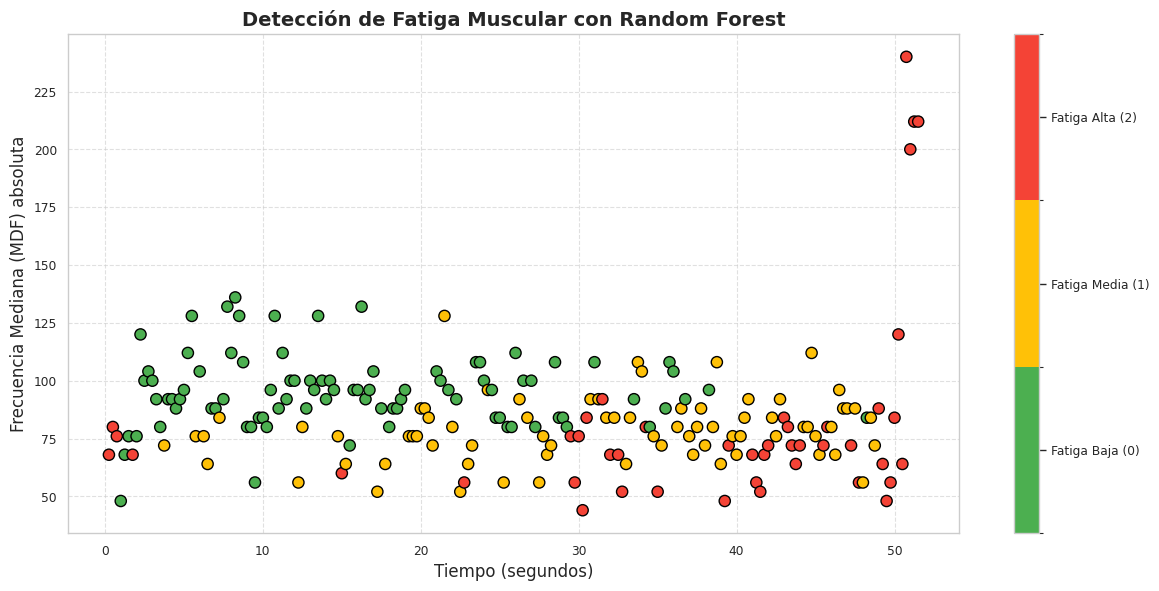

In [168]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd

if 'resultados' not in locals():
    print("❌ ERROR: Corre primero la celda de predicción.")
else:
    # 1. Detectar la columna de predicción (usamos la original, sin suavizar)
    posibles_cols = ['fatiga_predicha', 'prediccion', 'pred', 'label_pred', 'clase_predicha', 'nivel_fatiga_predicho', 'label']
    col_pred = next((c for c in posibles_cols if c in resultados.columns), None)
    if col_pred is None:
        col_pred = resultados.columns[-1]

    # 2. Configurar la figura
    plt.figure(figsize=(12, 6))

    # 3. FORZAR COLORES SÓLIDOS Y BARRA DISCRETA (Estilo GitHub)
    cmap = mcolors.ListedColormap(['#4CAF50', '#FFC107', '#F44336']) # Verde, Amarillo, Rojo
    bounds = [-0.5, 0.5, 1.5, 2.5]
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    # 4. Graficar (alpha=1.0 para que NO se vean pálidos)
    scatter = plt.scatter(resultados['time_s'], resultados['MDF'],
                          c=resultados[col_pred], # Usamos la predicción cruda
                          cmap=cmap,
                          norm=norm,
                          edgecolors='black',
                          alpha=1.0,
                          s=65,
                          linewidths=1)

    # 5. Barra de colores con bloques exactos
    cbar = plt.colorbar(scatter, ticks=[0, 1, 2], spacing='proportional')
    cbar.ax.set_yticklabels(['Fatiga Baja (0)', 'Fatiga Media (1)', 'Fatiga Alta (2)'])

    # 6. Estética idéntica
    plt.title("Detección de Fatiga Muscular con Random Forest", fontsize=14, fontweight='bold')
    plt.xlabel("Tiempo (segundos)", fontsize=12)
    plt.ylabel("Frecuencia Mediana (MDF) absoluta", fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

In [169]:
import pandas as pd

if "resultados" not in globals():
    raise NameError("Corre primero la celda de predicción.")

# 1. Detectar la columna
posibles_cols = ['nivel_fatiga_predicho', 'fatiga_predicha', 'prediccion', 'pred', 'label_pred', 'clase_predicha']
col_pred = next((c for c in posibles_cols if c in resultados.columns), None)

if col_pred is None:
    raise KeyError(f"No encuentro la columna de predicción. Columnas: {resultados.columns.tolist()}")

resultados[col_pred] = pd.to_numeric(resultados[col_pred], errors='coerce').astype('Int64')

# 2. Reporte con búsqueda de fatiga sostenida
def analizar_resultados_fatiga(df_resultados, col_pred):
    total_ventanas = len(df_resultados)
    tiempo_total = df_resultados['time_s'].max()

    conteos = df_resultados[col_pred].value_counts().to_dict()
    pct_0 = (conteos.get(0, 0) / total_ventanas) * 100
    pct_1 = (conteos.get(1, 0) / total_ventanas) * 100
    pct_2 = (conteos.get(2, 0) / total_ventanas) * 100

    # Buscar fatiga severa sostenida (en bloques de 4 ventanas ~ 1 segundo)
    df_estable = df_resultados[df_resultados['time_s'] > 1.5].copy()
    df_estable['bloque'] = df_estable.index // 4

    fatiga_sostenida = df_estable.groupby('bloque')[col_pred].mean()
    bloques_fatiga = fatiga_sostenida[fatiga_sostenida >= 1.5].index

    print("==========================================================")
    print("📊 REPORTE NUMÉRICO DEL PACIENTE")
    print("==========================================================")
    print(f"⏱️ Duración total de la prueba analizada: {tiempo_total:.2f} segundos")
    print(f"🟢 Estado Basal / Baja Fatiga (Clase 0) : {pct_0:.1f}% del tiempo")
    print(f"🟡 Transición / Fatiga Media (Clase 1)  : {pct_1:.1f}% del tiempo")
    print(f"🔴 Fallo / Fatiga Severa (Clase 2)      : {pct_2:.1f}% del tiempo")

    print("\n==========================================================")
    print("📝 ANÁLISIS CUALITATIVO / FISIOLÓGICO AUTOMATIZADO")
    print("==========================================================")

    if len(bloques_fatiga) > 0:
        primer_bloque = bloques_fatiga[0]
        inicio_clase_2 = df_estable[df_estable['bloque'] == primer_bloque]['time_s'].iloc[0]

        print(f"El músculo recto femoral del sujeto inició la prueba en un estado de bajo "
              f"reclutamiento compensatorio. A los {inicio_clase_2:.2f} segundos, el algoritmo detectó "
              f"la transición fisiológica sostenida hacia una fatiga periférica aguda (Clase 2).")
        print(f"A partir de este umbral, los marcadores espectrales indican una acumulación crítica "
              f"de metabolitos. El paciente permaneció el {pct_2:.1f}% del tiempo en este estado crítico.")
    else:
        print(f"Durante los {tiempo_total:.2f} segundos de la prueba, el sujeto no alcanzó un umbral "
              f"sostenido de fatiga severa (Clase 2). Las características matemáticas sugieren "
              f"una alta resistencia a la carga, manteniendo una velocidad de conducción estable.")
    print("==========================================================")

analizar_resultados_fatiga(resultados, col_pred)

📊 REPORTE NUMÉRICO DEL PACIENTE
⏱️ Duración total de la prueba analizada: 51.50 segundos
🟢 Estado Basal / Baja Fatiga (Clase 0) : 43.2% del tiempo
🟡 Transición / Fatiga Media (Clase 1)  : 35.4% del tiempo
🔴 Fallo / Fatiga Severa (Clase 2)      : 21.4% del tiempo

📝 ANÁLISIS CUALITATIVO / FISIOLÓGICO AUTOMATIZADO
El músculo recto femoral del sujeto inició la prueba en un estado de bajo reclutamiento compensatorio. A los 29.25 segundos, el algoritmo detectó la transición fisiológica sostenida hacia una fatiga periférica aguda (Clase 2).
A partir de este umbral, los marcadores espectrales indican una acumulación crítica de metabolitos. El paciente permaneció el 21.4% del tiempo en este estado crítico.


In [170]:
import shutil
import os
from pathlib import Path

# 1. Copiar el modelo a tu Drive
origen = 'modelo_fatiga_rf.pkl'
destino = '/content/drive/MyDrive/EMG_RAW data_procesada/modelo_fatiga_rf.pkl'

if os.path.exists(origen):
    shutil.copy(origen, destino)
    print(f"✅ ¡Modelo guardado PERMANENTEMENTE en tu Drive: {destino}!")
else:
    print("❌ No se encontró el modelo en la memoria temporal. Vuelve a correr la celda [166].")

✅ ¡Modelo guardado PERMANENTEMENTE en tu Drive: /content/drive/MyDrive/EMG_RAW data_procesada/modelo_fatiga_rf.pkl!
